# European caQTL benchmark: full ChromBPNet set and AlphaGenome test subset

Compare **cis-Mamba (nomlm_maskonly), AlphaGenomeAtlas, EpiBERT, ChromBPNet,
and Enformer** on the published European hg38 `var.isused` benchmark:
**95,065 SNPs = 7,900 positives + 87,165 controls**. Preserve the published
labels (`p < 1e-6` positive; `p > 1e-3` control) and source row order.

The analysis reports AUPRC (average precision) overall and within **Generic,
Other, and Specific** peak strata, followed by signed effect-size correlations
and observed-versus-predicted plots. The final analysis cell repeats everything
on AlphaGenome's **31,621-variant** test subset using the same scores and strata.

This notebook reads completed prediction artifacts and computes metrics locally.
It does not launch inference, query Atlas, modify source files, or write separate
result files. Missing files/columns, unfinished jobs, nonfinite scores, or row
mismatches raise errors; no model or variant is silently dropped. Run with the
`caduceus` Python environment after the three prediction jobs have finished.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import average_precision_score
from IPython.display import display

DATA = Path('/data1/lesliec/sarthak/data/joint_playground/caQTL')
SOURCE = DATA / 'caqtls.eu.lcls.benchmarking.all.tsv'
PEAK_CACHE = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl/dsQTL_benchmark8_cache')
PEAK_FILE = PEAK_CACHE / 'gm12878_merged.tsv.gz'
PEAK_SETTINGS = PEAK_CACHE / 'peaks.done.json'
CIS_PATH = DATA / 'nomlm_maskonly_gm12878_caqtl_varisused.npy'
EPI_PATH = DATA / 'epibert_caqtl_varisused.npy'
ATLAS_DIR = DATA / 'alphagenome_atlas_caqtl_varisused'
ATLAS_TABLE = ATLAS_DIR / 'alphagenome_atlas_caqtl.tsv'
ATLAS_MANIFEST = ATLAS_DIR / 'alphagenome_atlas_caqtl.json'

SPECIFICITY_CUTOFF = 68  # Fixed from dsQTL benchmark 10, never refit on these variants.
STRATA = ['Generic', 'Other', 'Specific']
GROUPS = ['Overall', *STRATA]
AG_TEST_CHROMS = {'chr3', 'chr6', 'chr9', 'chr12', 'chr16', 'chr18', 'chr19', 'chr21'}
# Primary paper comparison uses positives. All/Controls are descriptive alternatives.
EFFECT_POPULATION = 'Positives'  # 'Positives', 'All', or 'Controls'

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

def require(condition, message):
    if not bool(condition):
        raise ValueError(message)

def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError('Required completed artifacts are missing:\n' +
                                '\n'.join(missing) +
                                '\nFinish the corresponding prediction/merge job; partial files are not used.')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

## Published variants and labels

Coordinates are **1-based hg38**; interval overlap below uses `position - 1`.
`var.allele1` is genomic REF and `var.allele2` is ALT for this set, as validated
by the inference runners. European `obs.beta` uses ALT as its effect allele;
there is **no Yoruba dsQTL sign flip**. Retain the published ChromBPNet/Enformer
score orientation. [eQTL Catalogue allele convention](https://www.ebi.ac.uk/eqtl/Data_access/)
and [European preprocessing](https://github.com/kundajelab/chrombpnet-figures/blob/main/src/figures_factory/Fig6/preprocessing/format_kumsaka_caqtls.ipynb).

In [2]:
require_files([SOURCE])
source = pd.read_csv(SOURCE, sep='\t')
KEY = ['var.chr', 'var.pos_hg38', 'var.allele1', 'var.allele2']
require(set(KEY + ['var.isused', 'obs.pval', 'obs.beta']) <= set(source),
        'Source table is missing required variant/label fields.')
used = source['var.isused'].astype(str).str.lower()
require(used.isin(['true', 'false']).all(), 'Unexpected var.isused encoding.')
q = source.loc[used.eq('true')].copy()
q.insert(0, 'source_row', q.index.to_numpy())
q = q.reset_index(drop=True)
q.insert(0, 'benchmark_row', np.arange(len(q)))
q['var.pos_hg38'] = pd.to_numeric(q['var.pos_hg38'], errors='raise')
require((q['var.pos_hg38'].ge(1) & q['var.pos_hg38'].eq(np.floor(q['var.pos_hg38']))).all(),
        'Expected positive integer hg38 positions.')
q['var.pos_hg38'] = q['var.pos_hg38'].astype(np.int64)
for column in ['var.allele1', 'var.allele2']:
    require(q[column].isin(list('ACGT')).all(), f'Non-SNV allele in {column}.')
require(q['var.allele1'].ne(q['var.allele2']).all(), 'Identical REF/ALT alleles.')
require(not q.duplicated(KEY).any(), 'Duplicate variant identities.')
p = pd.to_numeric(q['obs.pval'], errors='raise')
require((p.between(0, 1) & ((p < 1e-6) | (p > 1e-3))).all(),
        'var.isused contains a variant outside the positive/control p-value thresholds.')
q['label'] = (p < 1e-6).astype(np.int8)
q['pos0_hg38'] = q['var.pos_hg38'] - 1
q['variant_id'] = (q['var.chr'] + '_' + q['var.pos_hg38'].astype(str) + '_' +
                   q['var.allele1'] + '_' + q['var.allele2'] + '_hg38')
y = q['label'].to_numpy()
beta = pd.to_numeric(q['obs.beta'], errors='raise').to_numpy(dtype=np.float64)
require(np.isfinite(beta).all(), 'Missing/nonfinite observed beta in the European benchmark.')
require((len(q), int(y.sum())) == (95065, 7900), 'Published European benchmark size changed.')
SOURCE_SHA256 = sha256(SOURCE)
print(f'Full benchmark: {len(q):,} variants; {y.sum():,} positives; {(y == 0).sum():,} controls.')

Full benchmark: 95,065 variants; 7,900 positives; 87,165 controls.


## Reuse the genome-wide peak definitions from dsQTL benchmark 10

Annotate these caQTL coordinates directly against the **genome-wide merged
GM12878 DNase peak table**. The dsQTL variant annotations themselves are not reused.
Breadth is the number of tracks with a call in at least half of the merged peak's
constituent 128-bp bins. Keep the original genome-wide median cutoff of 68 tracks:

| Stratum | Definition |
|---|---|
| Generic | Inside a merged GM12878 peak with breadth >68 |
| Other | Outside the merged GM12878 peaks |
| Specific | Inside a merged GM12878 peak with breadth ≤68 |

These are relative breadth categories. “Specific” does not mean unique to GM12878.
“Other” does not mean outside the original ATAC caQTL peak. Every variant belongs
to exactly one of the three strata and remains in the overall benchmark.

In [3]:
require_files([PEAK_FILE, PEAK_SETTINGS])
peak_settings = json.loads(PEAK_SETTINGS.read_text())
require(peak_settings['fdr'] == 0.01 and peak_settings['gm_fraction'] == 0.30
        and peak_settings['merged_fraction'] == 0.50 and peak_settings['gm_indices'] == [12, 69],
        'Peak construction settings differ from dsQTL benchmark 10.')
peaks = pd.read_csv(PEAK_FILE, sep='\t')
require(peaks['median_breadth'].eq(SPECIFICITY_CUTOFF).all(), 'Specificity cutoff changed.')
require(peaks['breadth'].median() == SPECIFICITY_CUTOFF, 'Unexpected genome-wide peak median.')
np.testing.assert_array_equal(peaks['specificity'], np.where(
    peaks['breadth'] <= SPECIFICITY_CUTOFF, 'high_specificity', 'low_specificity'))
require(set(q['var.chr']) <= set(peaks['chrom']), 'Peak cache lacks a benchmark chromosome.')
require(not peaks['peak_id'].duplicated().any(), 'Duplicate merged peak IDs.')

q['stratum'] = 'Other'
q['merged_peak_id'] = ''
q['peak_breadth'] = np.nan
for chrom, rows in q.groupby('var.chr', sort=False):
    intervals = peaks.loc[peaks['chrom'].eq(chrom)].sort_values('start')
    starts, ends = intervals['start'].to_numpy(), intervals['end'].to_numpy()
    require((starts < ends).all() and (starts[1:] >= ends[:-1]).all(),
            f'Merged peak intervals are invalid or overlapping on {chrom}.')
    pos = rows['pos0_hg38'].to_numpy()
    j = np.searchsorted(starts, pos, side='right') - 1
    overlap = (j >= 0) & (pos < ends[np.maximum(j, 0)])  # [start, end)
    row_ids = rows.index.to_numpy()[overlap]
    matched = intervals.iloc[j[overlap]]
    q.loc[row_ids, 'merged_peak_id'] = matched['peak_id'].to_numpy()
    q.loc[row_ids, 'peak_breadth'] = matched['breadth'].to_numpy()
    q.loc[row_ids, 'stratum'] = np.where(matched['breadth'] <= SPECIFICITY_CUTOFF,
                                       'Specific', 'Generic')
require(q['stratum'].isin(STRATA).all(), 'Unassigned specificity stratum.')
stratum = q['stratum'].to_numpy()

def cohort_masks(cohort):
    cohort = np.asarray(cohort, dtype=bool)
    require(cohort.shape == (len(q),), 'Cohort mask has the wrong shape.')
    masks = {'Overall': cohort}
    masks.update({name: cohort & (stratum == name) for name in STRATA})
    require(sum(int(masks[name].sum()) for name in STRATA) == int(cohort.sum()),
            'Specificity groups do not partition the cohort.')
    return masks

def cohort_counts(cohort):
    rows = []
    for group, mask in cohort_masks(cohort).items():
        n, positive = int(mask.sum()), int(y[mask].sum())
        rows.append({'Stratum': group, 'Variants': n, 'Positives': positive,
                     'Controls': n - positive, 'Chance AP': positive / n if n else np.nan})
    return pd.DataFrame(rows).set_index('Stratum').loc[GROUPS]

full_mask = np.ones(len(q), dtype=bool)
full_counts = cohort_counts(full_mask)
display(full_counts)
np.testing.assert_array_equal(full_counts.loc[STRATA, 'Variants'], [56566, 27152, 11347])
print(f'Peak-table SHA256: {sha256(PEAK_FILE)}')
del peaks

,Variants,Positives,Controls,Chance AP
Stratum,,,,
Overall,95065,7900,87165,0.083101
Generic,56566,4696,51870,0.083018
Other,27152,1826,25326,0.067251
Specific,11347,1378,9969,0.121442


Peak-table SHA256: dd08bdd6d6c1eb260f6c04047ba6808f720b3a69672c880bda0c5275dc6554f5


## Model scores

Keep benchmark 10's model-specific scoring choices, using the available European
prediction artifacts. Windows are fixed before examining the results.

| Model | AUPRC score | Signed effect for correlation |
|---|---|---|
| cis-Mamba, GM12878 DNase | Absolute log₂(ALT/REF), 500 bp | Signed log₂(ALT/REF) |
| AlphaGenomeAtlas, GM12878 DNase | Absolute native 501-bp score | log₂((ALT sum + 1)/(REF sum + 1)) |
| EpiBERT, GM12878 ATAC | Absolute ALT−REF sum, four 128-bp bins | Signed ALT−REF sum, 512 bp |
| ChromBPNet DNase and ATAC (572M/50M) | Separate IPS and absolute-logFC arms | Published signed logFC per track |
| Enformer GM12878 DNase | Published local absolute-logFC and global absolute-SAR arms | Corresponding published signed score |

ChromBPNet IPS is a magnitude/prioritization score; its separate classification
arm is not treated as a signed effect size. Each ChromBPNet track appears once
in the effect-size plots. Enformer's published local score uses its original
1,024-bp window and +1 pseudocount (preprocessing bins `444:452`), rather than
pretending it is the 2,048-bp Enformer array readout from dsQTL benchmark 10.

cis-Mamba and EpiBERT use measured accessibility context with a central mask
(1,000 and 1,536 bp, respectively). AlphaGenomeAtlas, ChromBPNet and Enformer
use DNA sequence inputs. This comparison therefore includes different input
information as well as different models and score definitions.

In [4]:
# Explicit expected columns double as failing placeholders if a future source table
# lacks a baseline. Supply the requested column; do not substitute zeros or skip it.
classification_scores, effect_scores = {}, {}
colors, effect_units, score_definitions = {}, {}, {}

def numeric_column(frame, column):
    if column not in frame:
        raise KeyError(f'Missing required score column (placeholder): {column}. '
                       'Obtain this score before running the complete benchmark.')
    values = pd.to_numeric(frame[column], errors='raise').to_numpy(dtype=np.float64)
    require(np.isfinite(values).all(), f'{column}: missing/nonfinite values; no rows are dropped.')
    return values

def add_classification(name, values, color, definition):
    values = np.asarray(values, dtype=np.float64)
    require(values.shape == (len(q),) and np.isfinite(values).all() and (values >= 0).all(),
            f'Invalid classification scores for {name}.')
    require(name not in classification_scores, f'Duplicate classification arm: {name}')
    classification_scores[name] = values
    colors[name] = color
    score_definitions[name] = definition

def add_effect(name, values, color, unit):
    values = np.asarray(values, dtype=np.float64)
    require(values.shape == (len(q),) and np.isfinite(values).all(), f'Invalid effects for {name}.')
    require(name not in effect_scores, f'Duplicate effect arm: {name}')
    effect_scores[name] = values
    colors[name] = color
    effect_units[name] = unit

CBP_TRACKS = [
    ('ChromBPNet DNase', 'encsr000emt', '#8C6D31'),
    ('ChromBPNet ATAC 572M', 'encsr637xsc', '#A77963'),
    ('ChromBPNet ATAC 50M', 'encsr637xsc_50m', '#BD9E39'),
]
for name, track, color in CBP_TRACKS:
    prefix = f'pred.chrombpnet.{track}.variantscore.'
    logfc = numeric_column(q, prefix + 'logfc')
    ips = numeric_column(q, prefix + 'ips')
    add_classification(name + ' |logFC|', np.abs(logfc), color, prefix + 'logfc; absolute value')
    add_classification(name + ' IPS', np.abs(ips), color, prefix + 'ips; absolute value')
    add_effect(name, logfc, color, 'Published signed logFC')

for name, suffix, unit in [
    ('Enformer local logFC', 'local_logfc', 'Published signed local logFC'),
    ('Enformer global SAR', 'global_sar', 'Published signed global SAR'),
]:
    column = 'pred.enformer.encsr000emt.variantscore.' + suffix
    score = numeric_column(q, column)
    add_classification(name, np.abs(score), '#DD8452', column + '; absolute value')
    add_effect(name, score, '#DD8452', unit)

print(f'Validated {len(classification_scores)} published baseline classification arms; no missing values.')

Validated 8 published baseline classification arms; no missing values.


## Load complete cis-Mamba, EpiBERT and Atlas outputs

Require the final output paths and completion manifests. Verify source hashes,
variant coordinates, REF/ALT alleles, labels, and original row identities before
combining models. Compute cis-Mamba and EpiBERT effects from their saved paired
profiles, then cross-check the producers' exported scores. Arrays are memory
mapped and reduced in blocks; full EpiBERT profiles are not copied into RAM.

In [5]:
def read_json(path):
    return json.loads(Path(path).read_text())

def aligned_scores(path, row_column):
    frame = pd.read_csv(path, sep='\t')
    require(len(frame) == len(q), f'{path}: expected the complete benchmark.')
    np.testing.assert_array_equal(frame[row_column], np.arange(len(q)), err_msg=str(path))
    for column in ['source_row', *KEY, 'label']:
        np.testing.assert_array_equal(frame[column], q[column], err_msg=f'{path}: {column}')
    for column in ['obs.beta', 'obs.pval']:
        np.testing.assert_allclose(frame[column], q[column], rtol=1e-12, atol=0,
                                   err_msg=f'{path}: {column}')
    return frame

def profile_sums(path, expected_bins, lo, hi):
    array = np.load(path, mmap_mode='r', allow_pickle=False)
    require(array.shape == (len(q), expected_bins, 2) and array.dtype == np.float32,
            f'{path}: unexpected profile shape/dtype: {array.shape}, {array.dtype}')
    require(0 <= lo < hi <= expected_bins, 'Invalid readout window.')
    totals = np.empty((len(q), 2), dtype=np.float64)
    for start in range(0, len(q), 1024):
        block = np.asarray(array[start:start + 1024, lo:hi, :], dtype=np.float64)
        require(np.isfinite(block).all() and (block >= 0).all(),
                f'{path}: invalid or incomplete profiles near row {start}.')
        totals[start:start + len(block)] = block.sum(axis=1)
    return totals

required_predictions = [
    CIS_PATH, CIS_PATH.with_suffix('.scores.tsv.gz'), CIS_PATH.with_suffix('.run.json'),
    EPI_PATH, EPI_PATH.with_suffix('.scores.tsv.gz'), EPI_PATH.with_suffix('.json'),
    ATLAS_TABLE, ATLAS_MANIFEST,
]

In [6]:
display(pd.DataFrame({'Required artifact': [str(p) for p in required_predictions],
                      'Exists': [p.is_file() for p in required_predictions]}))
require_files(required_predictions)

,Required artifact,Exists
0,/data1/lesliec/sarthak/data/joint_playground/c...,True
1,/data1/lesliec/sarthak/data/joint_playground/c...,True
2,/data1/lesliec/sarthak/data/joint_playground/c...,True
3,/data1/lesliec/sarthak/data/joint_playground/c...,True
4,/data1/lesliec/sarthak/data/joint_playground/c...,True
5,/data1/lesliec/sarthak/data/joint_playground/c...,True
6,/data1/lesliec/sarthak/data/joint_playground/c...,True
7,/data1/lesliec/sarthak/data/joint_playground/c...,True


In [7]:
cis_meta = read_json(CIS_PATH.with_suffix('.run.json'))
require(cis_meta['status'] == 'complete' and cis_meta['benchmark_rows'] == [0, len(q)],
        'cis-Mamba run is incomplete or covers only part of the benchmark.')
require(cis_meta['variants_sha256'] == SOURCE_SHA256, 'cis-Mamba source table changed.')
require(cis_meta['genome_build'] == 'hg38' and cis_meta['source_position_base'] == 1
        and cis_meta['channels'] == ['REF (var.allele1)', 'ALT (var.allele2)'],
        'cis-Mamba coordinate/allele convention differs.')
require(cis_meta['arguments']['mask_size'] == 1000 and cis_meta['arguments']['out_size'] == 500
        and cis_meta['arguments']['pool'] == 1, 'cis-Mamba scoring window differs.')
cis_saved = aligned_scores(CIS_PATH.with_suffix('.scores.tsv.gz'), 'prediction_row')
cis_pair = profile_sums(CIS_PATH, 500, 0, 500)
require((cis_pair > 0).all(), 'cis-Mamba logFC requires positive REF and ALT totals.')
cis_signed = np.log2(cis_pair[:, 1] / cis_pair[:, 0])
np.testing.assert_allclose(cis_pair / 500,
    cis_saved[['pred.ref_mean', 'pred.alt_mean']], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(cis_signed, numeric_column(cis_saved, 'pred.log2_alt_over_ref'),
                           rtol=1e-9, atol=1e-12)
np.testing.assert_allclose(np.abs(cis_signed), numeric_column(cis_saved, 'pred.abs_log2fc'),
                           rtol=1e-9, atol=1e-12)
CIS_NAME = 'cis-Mamba (500 bp logFC)'
add_classification(CIS_NAME, np.abs(cis_signed), '#2878B5',
                   '500 bp; |log2(sum(ALT)/sum(REF))|; no pseudocount')
add_effect(CIS_NAME, cis_signed, '#2878B5', 'Signed log2(ALT/REF), 500 bp')

In [8]:
epi_meta = read_json(EPI_PATH.with_suffix('.json'))
spec = epi_meta['spec']
require(epi_meta['status'] == 'complete' and epi_meta['rows_completed'] == len(q)
        and epi_meta['shape'] == [len(q), 4092, 2], 'EpiBERT merge is incomplete.')
require(spec['source_sha256'] == SOURCE_SHA256, 'EpiBERT source table changed.')
require(spec['genome_build'] == 'hg38' and spec['allele_axis'] == ['reference', 'alternate']
        and spec['score_bins_half_open'] == [2044, 2048] and spec['output_bin_bp'] == 128,
        'EpiBERT allele convention or scoring window differs.')
require(spec['atac_mask_bp_half_open'][1] - spec['atac_mask_bp_half_open'][0] == 1536,
        'EpiBERT accessibility mask differs.')
epi_saved = aligned_scores(EPI_PATH.with_suffix('.scores.tsv.gz'), 'prediction_row')
epi_pair = profile_sums(EPI_PATH, 4092, 2044, 2048)  # Exactly four bins, 512 bp.
epi_signed = epi_pair[:, 1] - epi_pair[:, 0]
np.testing.assert_allclose(epi_pair, epi_saved[['epibert_ref_sum_512', 'epibert_alt_sum_512']],
                           rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(epi_signed, numeric_column(epi_saved, 'epibert_delta_512'),
                           rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(np.abs(epi_signed), numeric_column(epi_saved, 'epibert_abs_delta_512'),
                           rtol=1e-10, atol=1e-10)
EPI_NAME = 'EpiBERT (512 bp delta)'
add_classification(EPI_NAME, np.abs(epi_signed), '#C44E52', '512 bp; |sum(ALT) - sum(REF)|')
add_effect(EPI_NAME, epi_signed, '#C44E52', 'Signed ALT - REF sum, 512 bp')

In [9]:
atlas_meta = read_json(ATLAS_MANIFEST)
require(atlas_meta['input_sha256'] == SOURCE_SHA256, 'Atlas source table changed.')
require(atlas_meta['rows'] == len(q) and atlas_meta['full_benchmark_rows'] == len(q)
        and atlas_meta['limit'] is None, 'Atlas export covers only part of the benchmark.')
require(atlas_meta['genome_build'] == 'hg38' and atlas_meta['position_base'] == 1
        and atlas_meta['context_bp'] == 1048576
        and atlas_meta['cell_types']['GM12878'] == 'EFO:0002784'
        and atlas_meta['score_columns'] == ['gm12878_dnase_score'], 'Atlas scorer metadata differs.')
atlas_saved = aligned_scores(ATLAS_TABLE, 'row_id')
require(atlas_saved['gm12878_dnase_status'].eq('ok').all()
        and atlas_saved['input_status'].eq('ready').all()
        and atlas_saved['orientation'].eq(1).all(), 'Atlas has missing/failed or reoriented variants.')
np.testing.assert_array_equal(atlas_saved['reference'], q['var.allele1'])
np.testing.assert_array_equal(atlas_saved['alternate'], q['var.allele2'])
atlas_signed = numeric_column(atlas_saved, 'gm12878_dnase_score')
np.testing.assert_allclose(np.abs(atlas_signed), numeric_column(atlas_saved, 'gm12878_dnase_abs_score'),
                           rtol=1e-12, atol=1e-14)
ATLAS_NAME = 'AlphaGenomeAtlas (501 bp logFC)'
add_classification(ATLAS_NAME, np.abs(atlas_signed), '#4C3B92',
                   'Native 501 bp DNase; |log2((sum(ALT)+1)/(sum(REF)+1))|')
add_effect(ATLAS_NAME, atlas_signed, '#4C3B92', 'Signed native log2FC, 501 bp + 1')

In [10]:
AP_NAMES = [CIS_NAME, ATLAS_NAME, EPI_NAME]
for name, _, _ in CBP_TRACKS:
    AP_NAMES.extend([name + ' |logFC|', name + ' IPS'])
AP_NAMES.extend(['Enformer local logFC', 'Enformer global SAR'])
EFFECT_NAMES = [CIS_NAME, ATLAS_NAME, EPI_NAME, *[x[0] for x in CBP_TRACKS],
                'Enformer local logFC', 'Enformer global SAR']
require(set(AP_NAMES) == set(classification_scores), 'Missing or unexpected classification arm.')
require(set(EFFECT_NAMES) == set(effect_scores), 'Missing or unexpected effect-size arm.')
require(all(np.isfinite(classification_scores[name]).all() for name in AP_NAMES)
        and all(np.isfinite(effect_scores[name]).all() for name in EFFECT_NAMES),
        'All models must cover all 95,065 variants before comparing metrics.')
print(f'Complete shared support: {len(q):,}/{len(q):,} variants for every model.')
display(pd.DataFrame({'Classification arm': AP_NAMES,
                      'Score definition': [score_definitions[name] for name in AP_NAMES]}))

Complete shared support: 95,065/95,065 variants for every model.


,Classification arm,Score definition
0,cis-Mamba (500 bp logFC),500 bp; |log2(sum(ALT)/sum(REF))|; no pseudocount
1,AlphaGenomeAtlas (501 bp logFC),Native 501 bp DNase; |log2((sum(ALT)+1)/(sum(R...
2,EpiBERT (512 bp delta),512 bp; |sum(ALT) - sum(REF)|
3,ChromBPNet DNase |logFC|,pred.chrombpnet.encsr000emt.variantscore.logfc...
4,ChromBPNet DNase IPS,pred.chrombpnet.encsr000emt.variantscore.ips; ...
5,ChromBPNet ATAC 572M |logFC|,pred.chrombpnet.encsr637xsc.variantscore.logfc...
6,ChromBPNet ATAC 572M IPS,pred.chrombpnet.encsr637xsc.variantscore.ips; ...
7,ChromBPNet ATAC 50M |logFC|,pred.chrombpnet.encsr637xsc_50m.variantscore.l...
8,ChromBPNet ATAC 50M IPS,pred.chrombpnet.encsr637xsc_50m.variantscore.i...
9,Enformer local logFC,pred.enformer.encsr000emt.variantscore.local_l...


## Metric definitions

**AUPRC** is `sklearn.metrics.average_precision_score`, not trapezoidal PR area.
Each panel uses identical rows across all models and shows its own positive
prevalence (chance AP). Different stratum prevalences affect AP, so compare models
within a panel rather than interpreting raw AP differences between strata alone.

**Effect size** uses signed predicted scores versus measured `obs.beta` among
significant positives by default, matching the caQTL papers. Pearson r is primary;
Spearman rho is included in the detailed table. `EFFECT_POPULATION` can select
all measured variants or controls for a separate descriptive analysis. Magnitude
scores are never correlated with signed beta. Pearson/Spearman values with fewer
than three observations or a constant vector are undefined; single-class AUPRC
panels are also marked undefined. No sign is selected by optimizing correlation.

In [11]:
def effect_population_mask(population):
    choices = {'Positives': y == 1, 'All': np.ones(len(q), dtype=bool), 'Controls': y == 0}
    require(population in choices, f'Unknown effect population: {population}')
    return choices[population] & np.isfinite(beta)

def safe_correlations(observed, predicted):
    if len(observed) < 3 or np.ptp(observed) == 0 or np.ptp(predicted) == 0:
        return np.nan, np.nan
    return float(pearsonr(observed, predicted)[0]), float(spearmanr(observed, predicted)[0])

def evaluate_cohort(cohort, label, population=EFFECT_POPULATION):
    masks = cohort_masks(cohort)
    counts = cohort_counts(cohort)
    ap = pd.DataFrame(index=pd.Index(AP_NAMES, name='Model'), columns=GROUPS, dtype=float)
    effect_rows = []
    for group, mask in masks.items():
        valid_classes = np.unique(y[mask]).size == 2
        for name in AP_NAMES:
            ap.loc[name, group] = (average_precision_score(y[mask], classification_scores[name][mask])
                                   if valid_classes else np.nan)
        effect_mask = mask & effect_population_mask(population)
        for name in EFFECT_NAMES:
            r, rho = safe_correlations(beta[effect_mask], effect_scores[name][effect_mask])
            effect_rows.append({'Model': name, 'Stratum': group, 'Population': population,
                                'N': int(effect_mask.sum()), 'Pearson r': r, 'Spearman rho': rho})
    effects = pd.DataFrame(effect_rows)
    return {'label': label, 'mask': np.asarray(cohort, dtype=bool).copy(), 'masks': masks,
            'population': population, 'counts': counts, 'ap': ap, 'effects': effects}

def show_effect_table(result):
    effects = result['effects']
    print(f"{result['label']} — signed effect sizes: {result['population']}")
    display(effects.drop_duplicates('Stratum').set_index('Stratum')[['N']].loc[GROUPS])
    display(effects.pivot(index='Model', columns='Stratum', values='Pearson r')
            .reindex(index=EFFECT_NAMES, columns=GROUPS).round(4))

In [12]:
def plot_auprc(result, order):
    fig, axes = plt.subplots(1, 4, figsize=(24, 7.5), sharey=True, sharex=True)
    positions = np.arange(len(order))
    for ax, group in zip(axes, GROUPS):
        values = result['ap'].loc[order, group].to_numpy()
        ax.barh(positions, np.nan_to_num(values, nan=0), color=[colors[name] for name in order])
        ax.set_yticks(positions, order)
        chance = result['counts'].loc[group, 'Chance AP']
        if np.isfinite(chance):
            ax.axvline(chance, color='#444444', linestyle=':', linewidth=1.5,
                       label=f'Chance AP = {chance:.3f}')
            ax.legend(loc='lower right', fontsize=8)
        for i, value in enumerate(values):
            text = f'{value:.3f}' if np.isfinite(value) else 'undefined'
            ax.text(min(value + .012, .99) if np.isfinite(value) else .015, i, text,
                    va='center', ha='right' if np.isfinite(value) and value > .96 else 'left', fontsize=8)
        row = result['counts'].loc[group]
        ax.set_title(f"{group}\nn={int(row['Variants']):,}; positives={int(row['Positives']):,}")
        ax.set(xlim=(0, 1), xlabel='AUPRC (average precision)')
        ax.grid(axis='x', alpha=.15)
        ax.set_axisbelow(True)
    axes[0].set_ylim(len(order) - .5, -.5)
    fig.suptitle(result['label'], fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, .95))
    plt.show()

STRATUM_COLORS = {'Generic': '#4C78A8', 'Other': '#A3A3A3', 'Specific': '#E45756'}

def plot_effect_sizes(result):
    ncols = 3
    nrows = math.ceil(len(EFFECT_NAMES) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4 * nrows), squeeze=False)
    mask = result['mask'] & effect_population_mask(result['population'])
    for ax, name in zip(axes.flat, EFFECT_NAMES):
        for group in STRATA:
            selected = mask & (stratum == group)
            ax.scatter(beta[selected], effect_scores[name][selected], s=5, alpha=.30,
                       color=STRATUM_COLORS[group], label=group, edgecolors='none', rasterized=True)
        r, _ = safe_correlations(beta[mask], effect_scores[name][mask])
        r_label = f'{r:.3f}' if np.isfinite(r) else 'undefined'
        ax.set_title(f'{name}\nPearson r = {r_label}; n = {int(mask.sum()):,}', fontsize=10)
        ax.axvline(0, color='#777777', linewidth=.6)
        ax.axhline(0, color='#777777', linewidth=.6)
        ax.set(xlabel='Observed caQTL beta (ALT effect)', ylabel=effect_units[name])
    for ax in list(axes.flat)[len(EFFECT_NAMES):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(.5, .96), markerscale=2)
    fig.suptitle(f"{result['label']} — signed effect sizes, {result['population'].lower()}", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, .93))
    plt.show()

## Full ChromBPNet `var.isused` benchmark

All 95,065 variants contribute to overall classification. Generic/Other/Specific
are a complete, disjoint partition of that same set. Model ordering is determined
once by full-set overall AP and retained in the AlphaGenome-subset panels below.

,Variants,Positives,Controls,Chance AP
Stratum,,,,
Overall,95065,7900,87165,0.083101
Generic,56566,4696,51870,0.083018
Other,27152,1826,25326,0.067251
Specific,11347,1378,9969,0.121442


,Overall,Generic,Other,Specific
Model,,,,
AlphaGenomeAtlas (501 bp logFC),0.3869,0.3983,0.3021,0.4577
ChromBPNet ATAC 572M |logFC|,0.3179,0.3274,0.2324,0.4019
Enformer local logFC,0.3048,0.3234,0.2143,0.3772
ChromBPNet ATAC 572M IPS,0.2995,0.2995,0.2342,0.4027
ChromBPNet DNase |logFC|,0.2902,0.2945,0.2129,0.3853
ChromBPNet ATAC 50M |logFC|,0.2853,0.2973,0.2030,0.3702
cis-Mamba (500 bp logFC),0.2852,0.2903,0.2073,0.3664
ChromBPNet ATAC 50M IPS,0.2747,0.2737,0.2137,0.3783
ChromBPNet DNase IPS,0.2693,0.2677,0.2101,0.3753


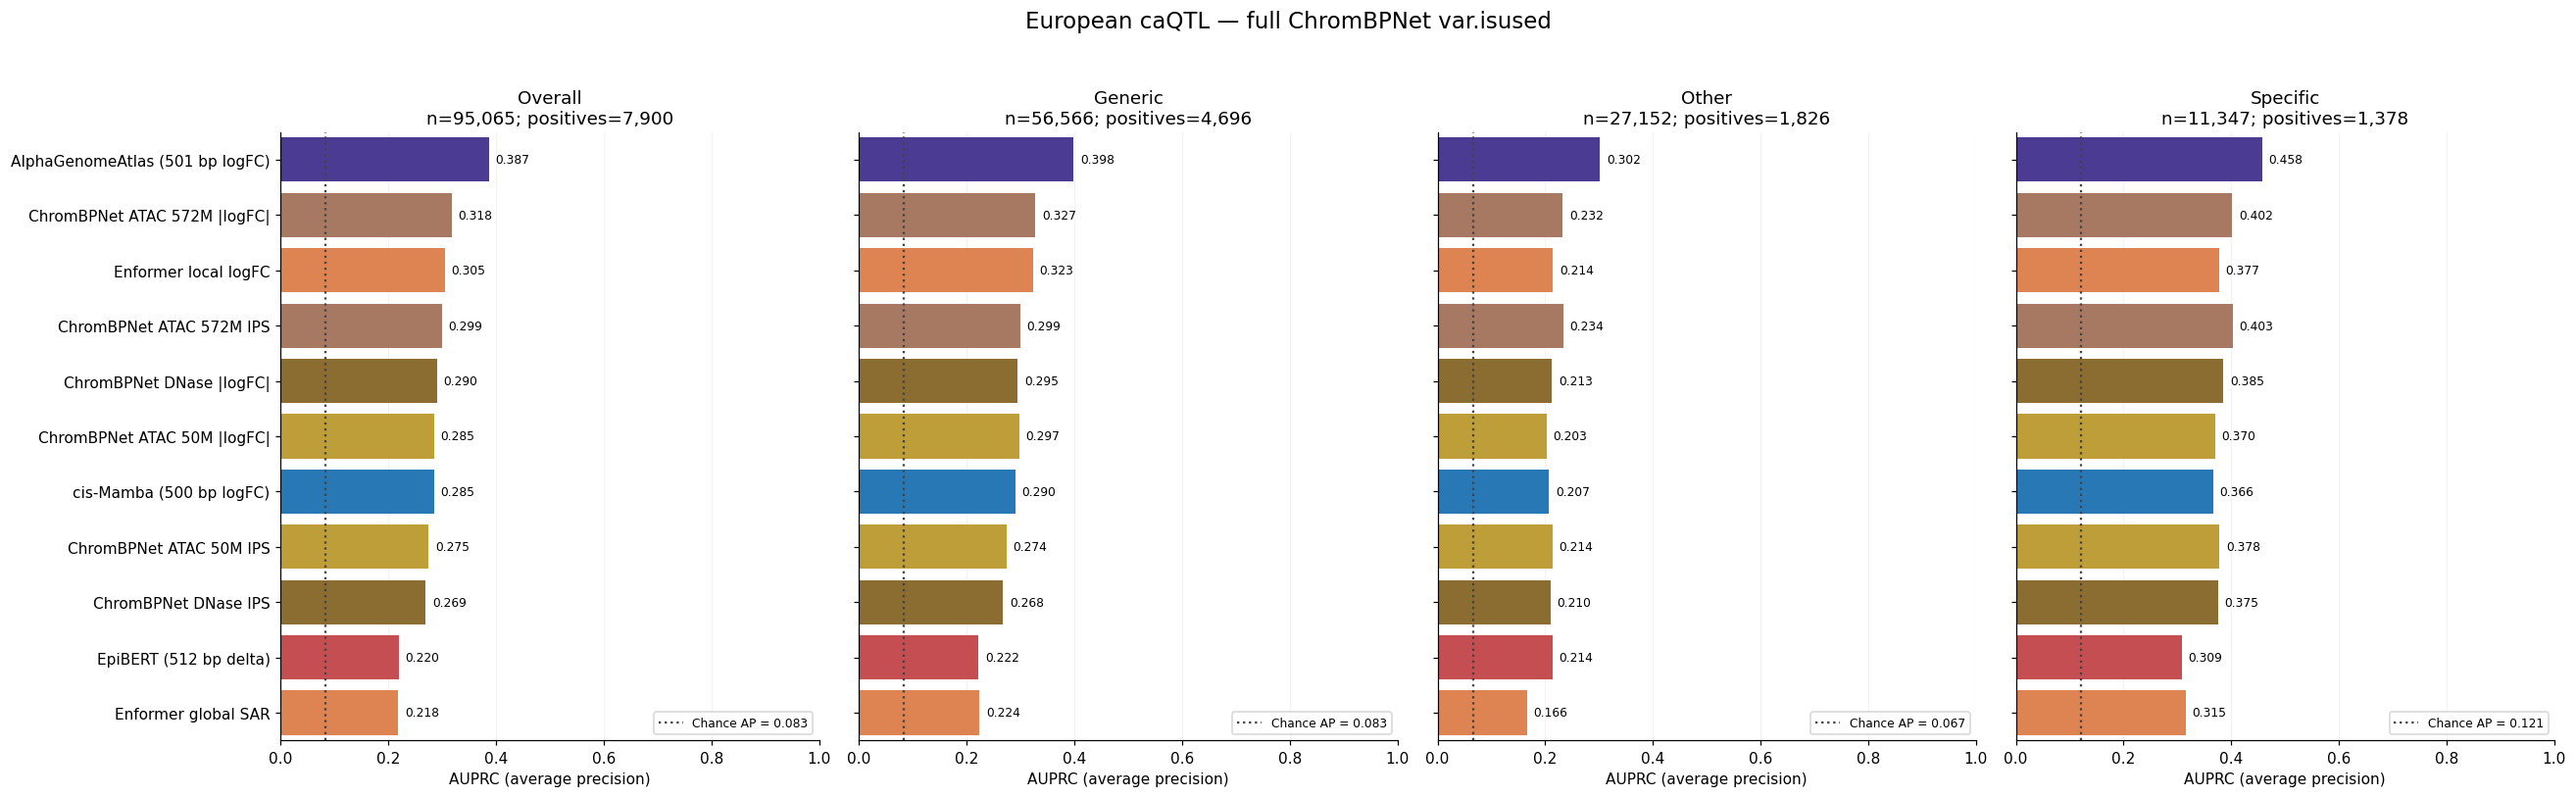

In [13]:
full_results = evaluate_cohort(full_mask, 'European caQTL — full ChromBPNet var.isused')
AP_ORDER = full_results['ap']['Overall'].sort_values(ascending=False, kind='stable').index.tolist()
display(full_results['counts'])
display(full_results['ap'].loc[AP_ORDER].round(4))
plot_auprc(full_results, AP_ORDER)

## Effect-size correlation on the full benchmark

By default, the scatterplots contain the **7,900 significant caQTLs**; point colour
denotes the same peak specificity categories used above. The table also gives
Pearson correlations within each stratum. Model scores have different units, so
the plots assess association with beta rather than one-to-one effect calibration.
Detailed Pearson/Spearman results are available in `full_results['effects']`.

European caQTL — full ChromBPNet var.isused — signed effect sizes: Positives


,N
Stratum,
Overall,7900
Generic,4696
Other,1826
Specific,1378


Stratum,Overall,Generic,Other,Specific
Model,,,,
cis-Mamba (500 bp logFC),0.4833,0.4900,0.4088,0.5526
AlphaGenomeAtlas (501 bp logFC),0.6044,0.6186,0.5139,0.6634
EpiBERT (512 bp delta),0.4705,0.5010,0.4128,0.4965
ChromBPNet DNase,0.5420,0.5571,0.4676,0.5822
ChromBPNet ATAC 572M,0.5503,0.5644,0.4764,0.5923
ChromBPNet ATAC 50M,0.5301,0.5463,0.4534,0.5703
Enformer local logFC,0.5230,0.5510,0.3974,0.5811
Enformer global SAR,0.4091,0.4344,0.2968,0.4828


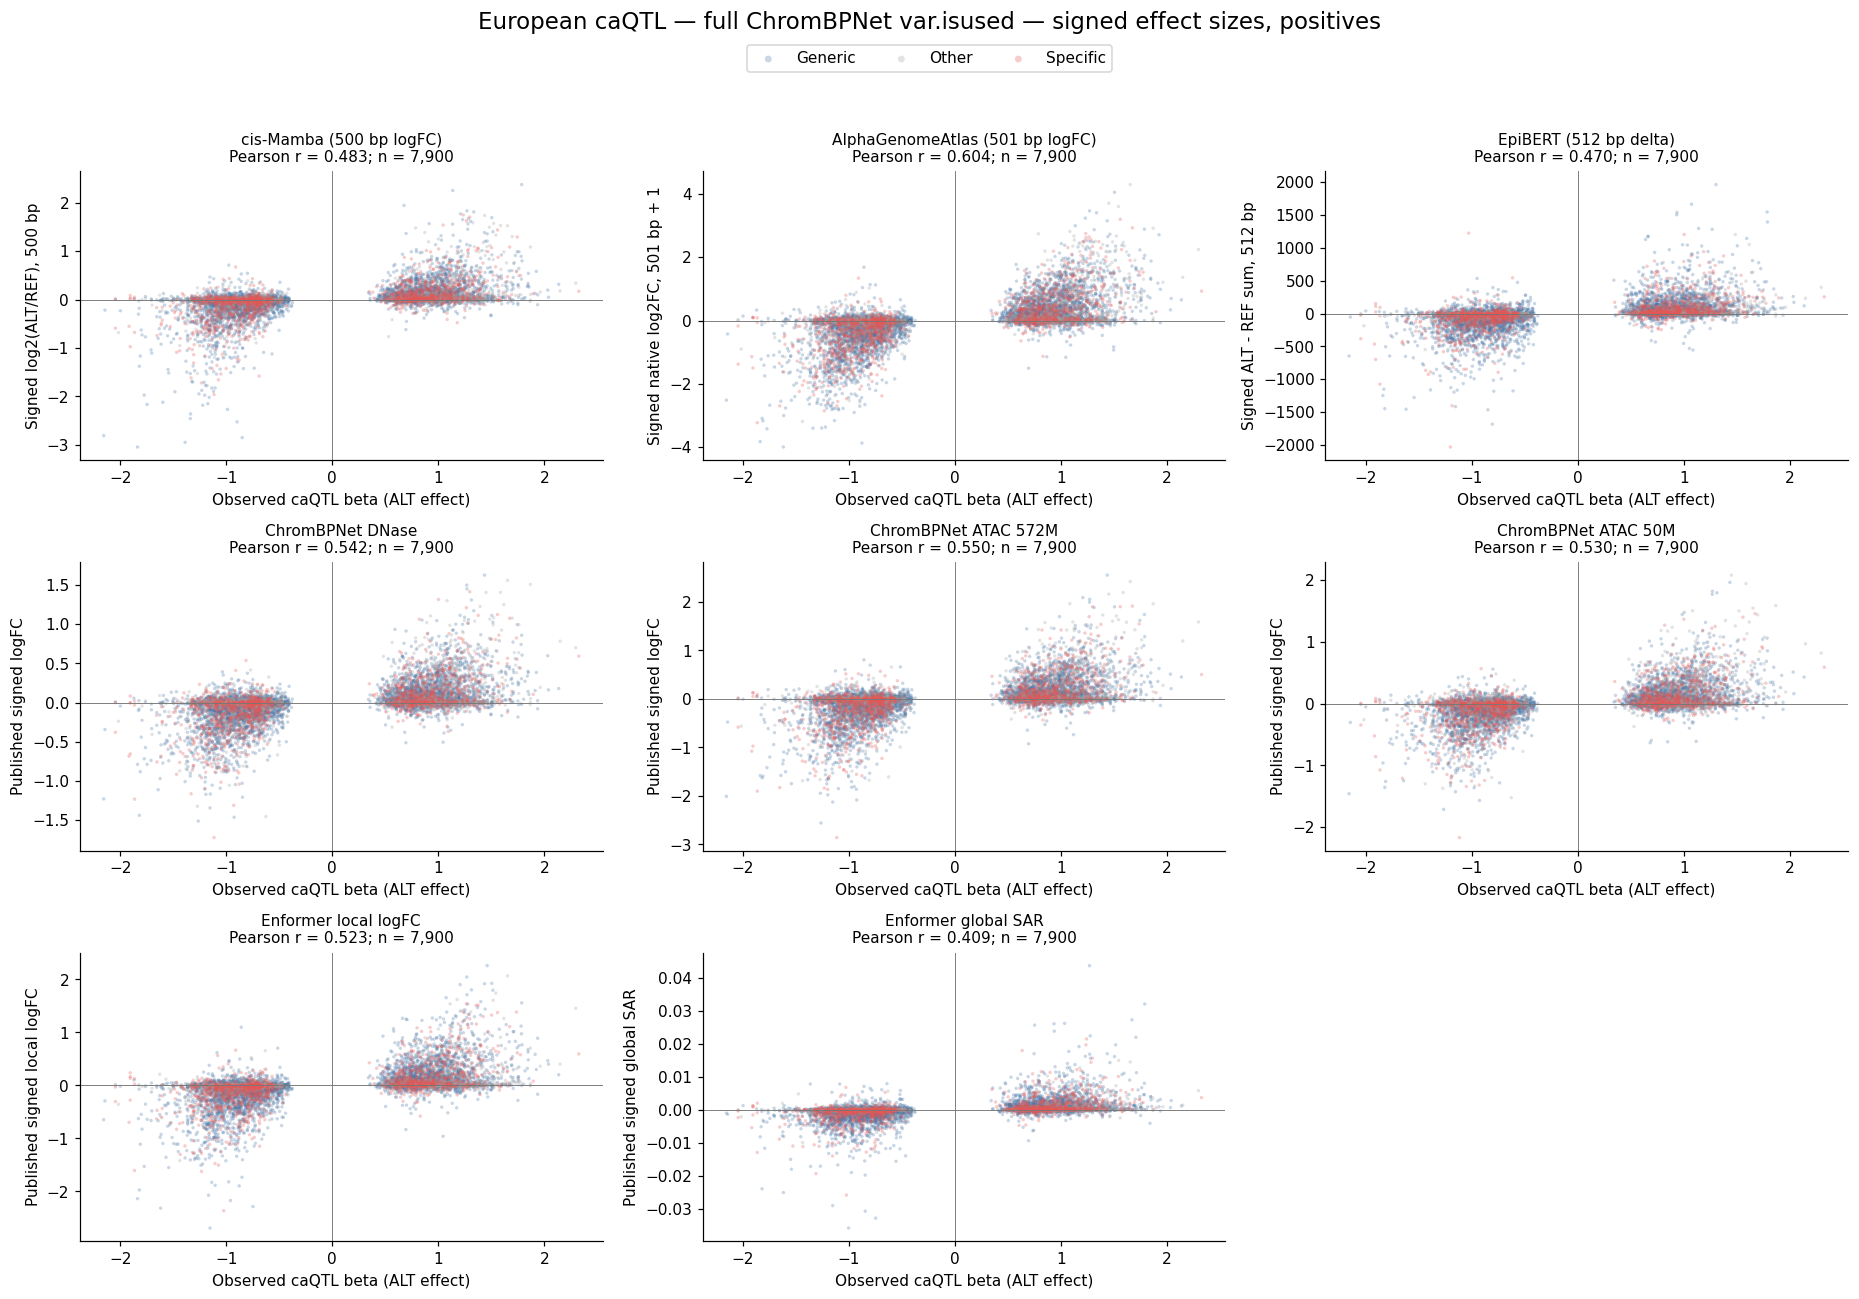

In [14]:
show_effect_table(full_results)
plot_effect_sizes(full_results)

## Repeat all evaluations on AlphaGenome's European test subset

Keep chromosomes **3, 6, 9, 12, 16, 18, 19, 21**, giving **31,621 variants:
2,618 positives and 29,003 controls**. Chromosome 9 is already absent from the
European `var.isused` set. These variants and labels were checked against the
authors' released [classification table](https://storage.googleapis.com/alphagenome/evals/caqtl_european_variant_causality_human_predictions.feather)
and [effect-size table](https://storage.googleapis.com/alphagenome/evals/caqtl_european_variant_coefficient_human_predictions.feather).

This cell **recomputes metrics**, using each model's unchanged scores, rather than
rerunning inference or changing every model to a 501-bp readout. The peak cutoff
also stays fixed. AlphaGenomeAtlas already uses the paper's native DNase scorer;
using its chromosome subset alone does not make every other scoring choice
identical to the paper. AlphaGenome's variant test split separates benchmark
development from evaluation; its distilled all-fold model is not a model trained
with these entire chromosomes held out.
[AlphaGenome paper and supplementary methods](https://www.nature.com/articles/s41586-025-10014-0).

,Variants,Positives,Controls,Chance AP
Stratum,,,,
Overall,31621,2618,29003,0.082793
Generic,19157,1587,17570,0.082842
Other,8707,585,8122,0.067187
Specific,3757,446,3311,0.118712


,Overall,Generic,Other,Specific
Model,,,,
AlphaGenomeAtlas (501 bp logFC),0.3628,0.3716,0.2820,0.4369
ChromBPNet ATAC 572M |logFC|,0.2961,0.3051,0.2181,0.3708
Enformer local logFC,0.2831,0.3007,0.1764,0.3691
ChromBPNet ATAC 572M IPS,0.2787,0.2787,0.2219,0.3760
ChromBPNet DNase |logFC|,0.2683,0.2717,0.1972,0.3574
ChromBPNet ATAC 50M |logFC|,0.2666,0.2787,0.1895,0.3390
cis-Mamba (500 bp logFC),0.2714,0.2765,0.2043,0.3383
ChromBPNet ATAC 50M IPS,0.2573,0.2562,0.2031,0.3545
ChromBPNet DNase IPS,0.2481,0.2442,0.1995,0.3530


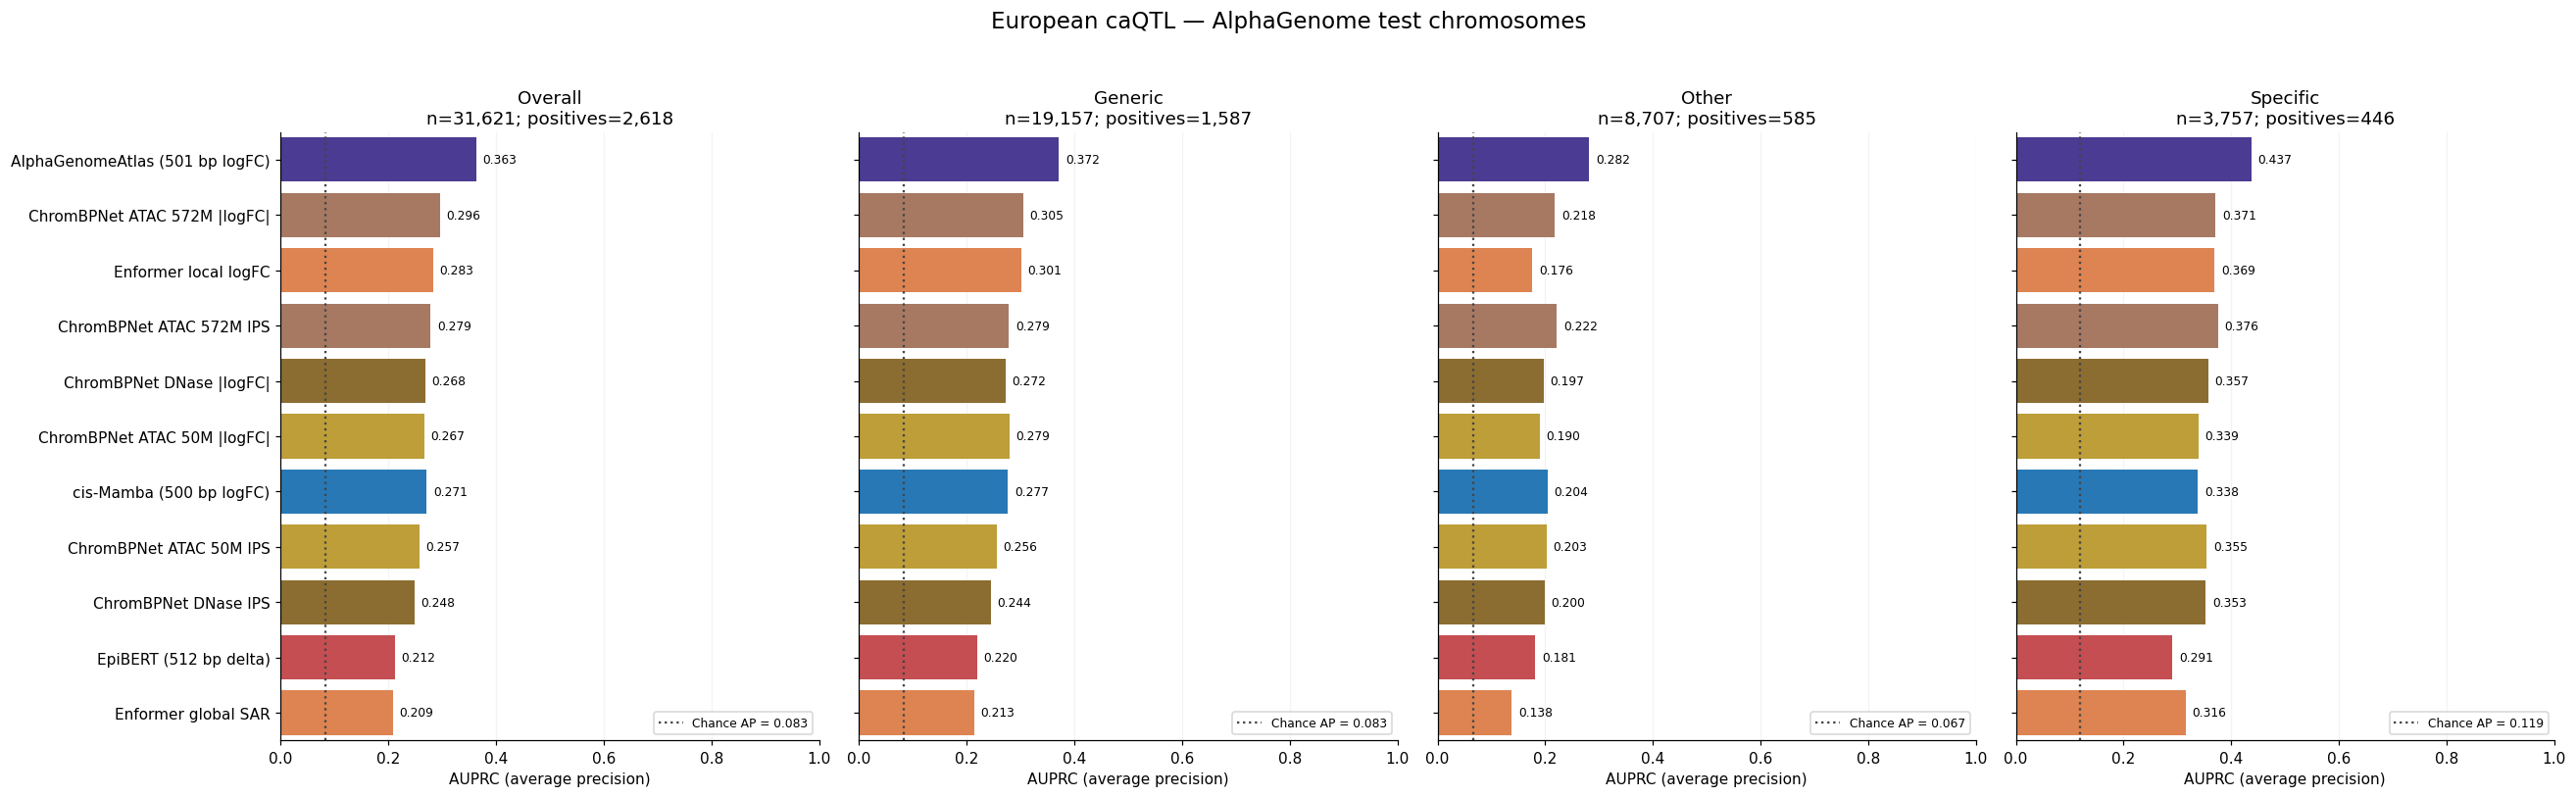

European caQTL — AlphaGenome test chromosomes — signed effect sizes: Positives


,N
Stratum,
Overall,2618
Generic,1587
Other,585
Specific,446


Stratum,Overall,Generic,Other,Specific
Model,,,,
cis-Mamba (500 bp logFC),0.4690,0.4755,0.4143,0.5209
AlphaGenomeAtlas (501 bp logFC),0.5901,0.6050,0.5144,0.6366
EpiBERT (512 bp delta),0.4440,0.4732,0.4232,0.4607
ChromBPNet DNase,0.5193,0.5322,0.4489,0.5598
ChromBPNet ATAC 572M,0.5249,0.5386,0.4497,0.5693
ChromBPNet ATAC 50M,0.5105,0.5251,0.4342,0.5544
Enformer local logFC,0.5078,0.5386,0.3745,0.5585
Enformer global SAR,0.3901,0.4147,0.2677,0.4647


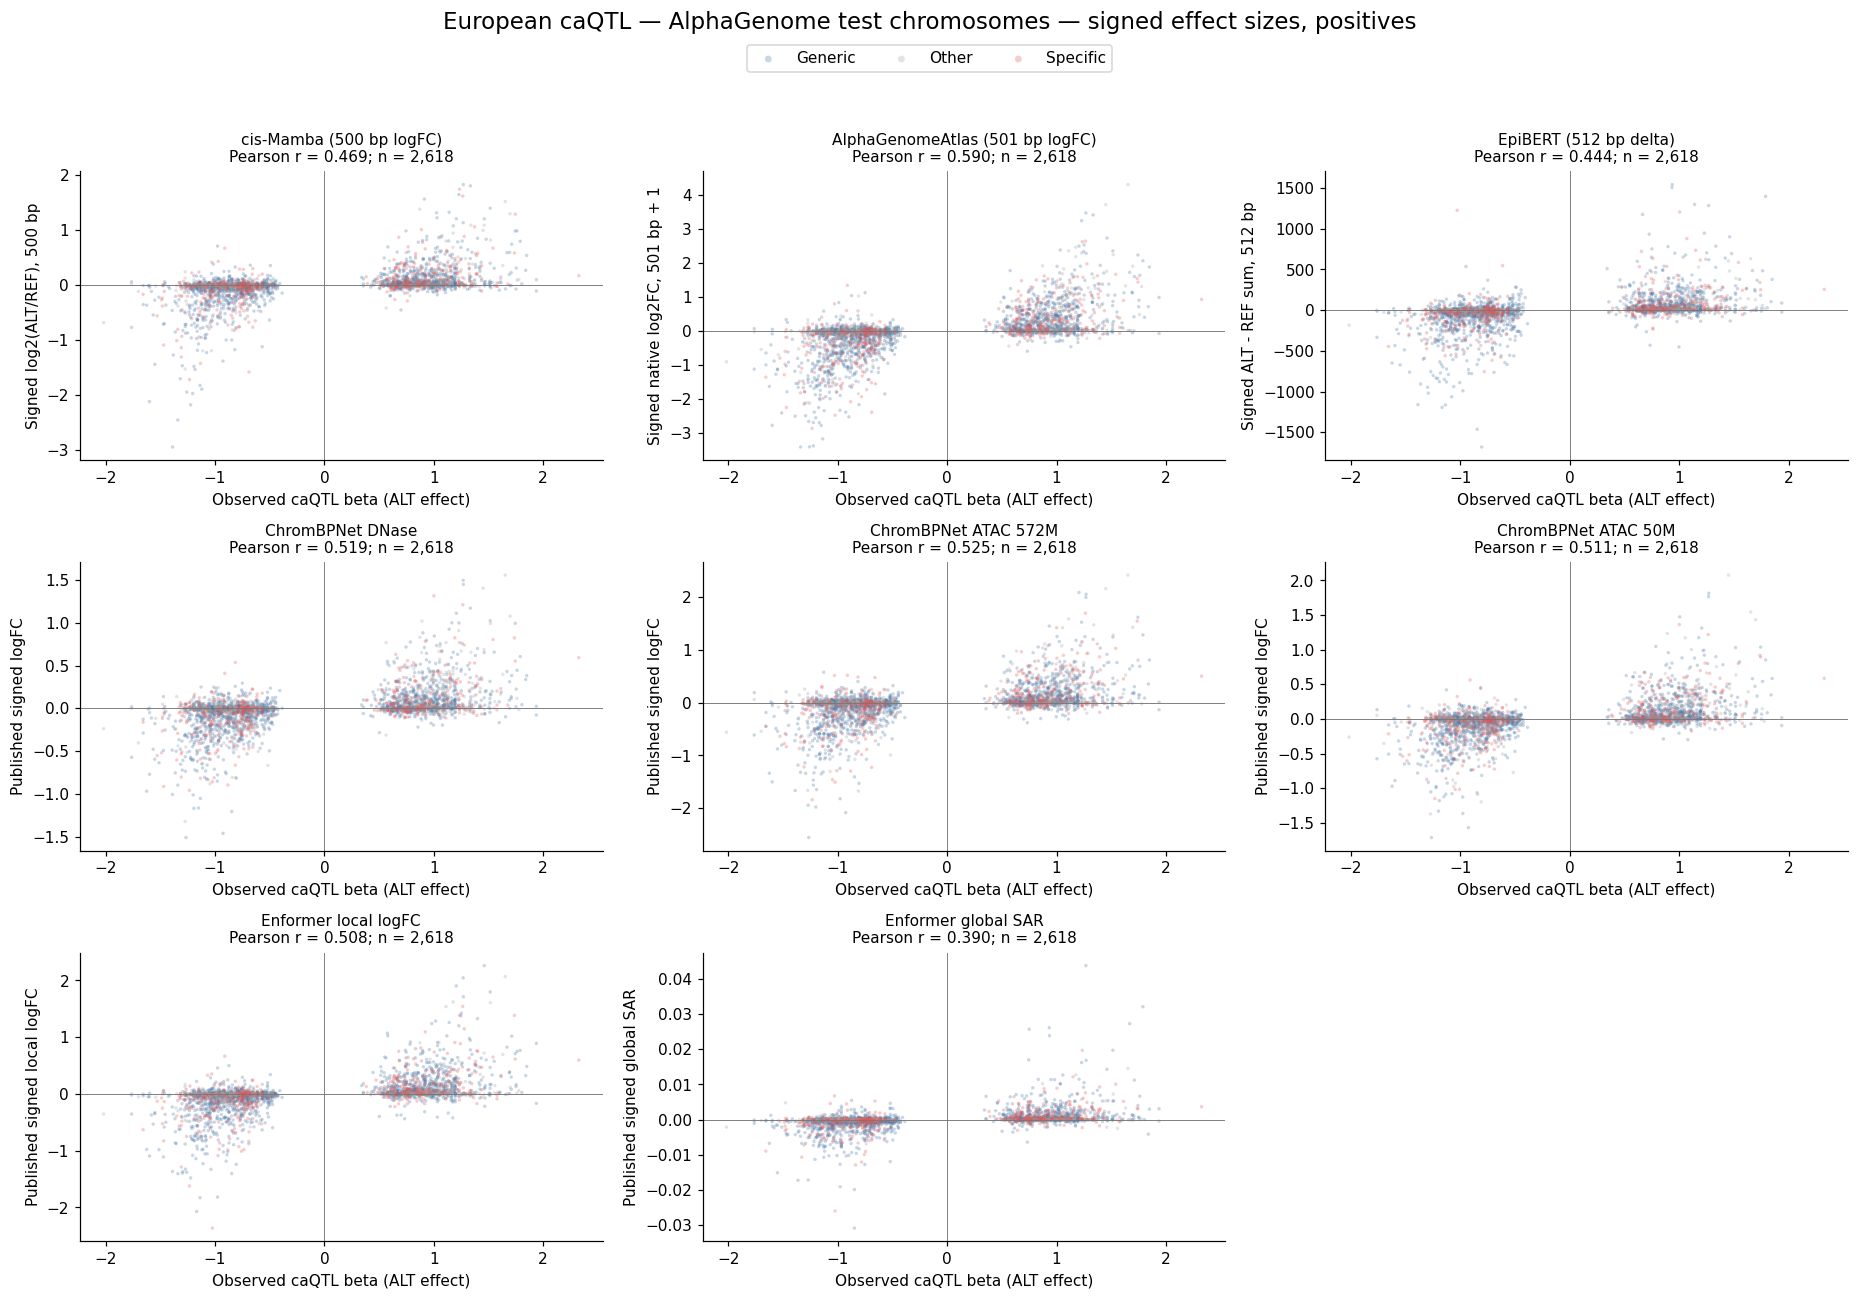

In [15]:
ag_mask = q['var.chr'].isin(AG_TEST_CHROMS).to_numpy()
require((int(ag_mask.sum()), int(y[ag_mask].sum())) == (31621, 2618),
        'AlphaGenome test subset no longer matches its released European benchmark.')
ag_results = evaluate_cohort(ag_mask, 'European caQTL — AlphaGenome test chromosomes')
np.testing.assert_array_equal(ag_results['counts'].loc[STRATA, 'Variants'], [19157, 8707, 3757])
display(ag_results['counts'])
display(ag_results['ap'].loc[AP_ORDER].round(4))
plot_auprc(ag_results, AP_ORDER)
show_effect_table(ag_results)
plot_effect_sizes(ag_results)

## Interpretation

This reproduces the published variant selection, including its existing peak
restriction, LD structure, and controls that may associate with another peak.
It is separate from the broader master variant list. Variant-level AP is a
ranking benchmark, not proof that every positive is causal or independent.

Specificity stratification measures performance within peaks of different breadth;
it does not establish prediction of a variant's differential effect across cell
types. The groups also have different class prevalences. Any uncertainty analysis
should account for correlated variants (for example, peak/locus cluster resampling).
No independent-variant confidence intervals or significance claims are made here.

The notebook deliberately requires complete shared support. Missing baseline
columns are explicit failing placeholders; missing run artifacts must be supplied
at the paths above. Do not fill failures with zeros or compare models on different
variant subsets. `full_results` and `ag_results` retain all tables in memory.

## Accessibility cutoff sweep: specific versus generic

This repeats the dsQTL cutoff sensitivity plot using the caQTL labels, cached
model scores, and GM12878 merged-peak annotations already validated above.
At each integer cutoff **k**, **Specific** means peak breadth **≤ k**, and
**Generic** means peak breadth **> k**. **Other is excluded from both panels**:
these variants lie outside the merged GM12878 DNase peaks, not necessarily
outside the original ATAC caQTL peaks. The earlier overall analysis still
includes Other. Membership in the two sweep groups partitions a fixed in-peak
population at every cutoff, shared across all models.

The default is the **full European var.isused cohort**, even if the preceding
cell evaluated the AlphaGenome subset. Set `SWEEP_COHORT = 'AlphaGenome test'`
to repeat this sweep on its test chromosomes. Run the data, annotation and
score-loading cells through the **Complete shared support** cell before this
section. No inference or remote requests are made. This appended section saves
its own plots, count tables and AP tables under `caQTL_benchmark5_cutoff_sweep/`.

The x axis decreases from the full panel size to 1 with log spacing. All integer
cutoffs are evaluated; the lines are connected estimates, not a fitted smoother.
Counts above each panel show its own positives and negatives at selected cutoffs.
Breadth counts accessible **tracks**, including replicates, not distinct cell types.
The original cutoff 68 and each panel's positive-fraction baseline are marked.
AUPRC is **average precision**, as elsewhere in this notebook.

All existing classification arms are included by default; edit `SWEEP_MODELS`
to simplify the plot. Colors match the earlier panels. Dashed IPS curves and
dash-dot Enformer global SAR distinguish alternative scores within a model.
Dotted segments flag fewer than 20 positives or negatives; single-class or
empty groups have undefined AP and remain blank. The count flag is not a power
criterion. This is descriptive, with no confidence bands: nested cutoffs are
not independent holdouts, and any uncertainty analysis must account for
correlated variants through paired peak/locus resampling.


In [11]:
from time import perf_counter

sweep_started = perf_counter()
SWEEP_COHORT = 'Full'  # 'Full' or 'AlphaGenome test'
SWEEP_MODELS = list(AP_NAMES)
SWEEP_MIN_CLASS_COUNT = 20  # display flag only; retains all scores/counts
require(SWEEP_COHORT in ['Full', 'AlphaGenome test'], 'Unknown sweep cohort.')
sweep_cohort = (full_mask.copy() if SWEEP_COHORT == 'Full' else
                q['var.chr'].isin(AG_TEST_CHROMS).to_numpy())
if SWEEP_COHORT == 'AlphaGenome test':
    require((int(sweep_cohort.sum()), int(y[sweep_cohort].sum())) == (31621, 2618),
            'AlphaGenome test-chromosome membership changed.')
sweep_slug = 'full' if SWEEP_COHORT == 'Full' else 'alphagenome_test'
SWEEP_OUT = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/caqtl') / 'caQTL_benchmark5_cutoff_sweep' / sweep_slug
SWEEP_OUT.mkdir(parents=True, exist_ok=True)

sweep_track_count = len(pd.read_csv(PEAK_CACHE / 'tracks.tsv', sep='\t'))
sweep_breadth = q['peak_breadth'].to_numpy(dtype=float)
sweep_in_peak = q['merged_peak_id'].fillna('').ne('').to_numpy()
np.testing.assert_array_equal(sweep_in_peak, q['stratum'].ne('Other').to_numpy())
sweep_support = sweep_cohort & sweep_in_peak
require(np.isfinite(sweep_breadth[sweep_support]).all(), 'Missing in-peak breadth.')
require((sweep_breadth[sweep_support] == np.floor(sweep_breadth[sweep_support])).all(),
        'Track breadth must be an integer.')
require(((sweep_breadth[sweep_support] >= 1) &
         (sweep_breadth[sweep_support] <= sweep_track_count)).all(), 'Invalid track breadth.')
require(bool(SWEEP_MODELS) and len(SWEEP_MODELS) == len(set(SWEEP_MODELS)),
        'Select at least one model, without duplicates.')
require(set(SWEEP_MODELS) <= set(classification_scores), 'Unknown classification arm.')
for name in SWEEP_MODELS:
    require(np.isfinite(classification_scores[name][sweep_support]).all(),
            f'{name}: nonfinite score on common sweep support.')
sweep_original_masks = cohort_masks(sweep_cohort)
np.testing.assert_array_equal(sweep_support & (sweep_breadth <= SPECIFICITY_CUTOFF),
                              sweep_original_masks['Specific'])
np.testing.assert_array_equal(sweep_support & (sweep_breadth > SPECIFICITY_CUTOFF),
                              sweep_original_masks['Generic'])

sweep_count_rows, sweep_score_rows = [], []
for cutoff in range(1, sweep_track_count + 1):
    for group, mask in [('Specific', sweep_support & (sweep_breadth <= cutoff)),
                        ('Generic', sweep_support & (sweep_breadth > cutoff))]:
        n = int(mask.sum())
        positive = int(y[mask].sum())
        negative = n - positive
        defined = positive > 0 and negative > 0
        sweep_count_rows.append(dict(cutoff=cutoff, group=group, variants=n,
            positives=positive, negatives=negative,
            prevalence=positive / n if n else np.nan,
            ap_defined=defined, low_count=min(positive, negative) < SWEEP_MIN_CLASS_COUNT,
            peak_clusters=int(q.loc[mask, 'merged_peak_id'].nunique())))
        for name in SWEEP_MODELS:
            ap = (average_precision_score(y[mask], classification_scores[name][mask])
                  if defined else np.nan)
            sweep_score_rows.append(dict(cutoff=cutoff, group=group, model=name, ap=ap))
    if cutoff % 100 == 0:
        print(f'Scored {cutoff}/{sweep_track_count} cutoffs.', flush=True)

sweep_counts = pd.DataFrame(sweep_count_rows)
sweep_results = pd.DataFrame(sweep_score_rows).merge(
    sweep_counts, on=['cutoff', 'group'], validate='many_to_one')
require(sweep_counts.groupby('cutoff').variants.sum().eq(int(sweep_support.sum())).all(),
        'Changing total sweep population across cutoffs.')
require(sweep_counts.groupby('cutoff').positives.sum().eq(int(y[sweep_support].sum())).all(),
        'Changing total sweep positive count across cutoffs.')
for group in ['Specific', 'Generic']:
    at_original = sweep_results[(sweep_results.cutoff == SPECIFICITY_CUTOFF) &
                                (sweep_results.group == group)].set_index('model')
    old_mask = sweep_original_masks[group]
    expected = [average_precision_score(y[old_mask], classification_scores[name][old_mask])
                if np.unique(y[old_mask]).size == 2 else np.nan for name in SWEEP_MODELS]
    np.testing.assert_allclose(at_original.loc[SWEEP_MODELS, 'ap'], expected,
                              rtol=0, atol=1e-12, equal_nan=True)

sweep_counts.to_csv(SWEEP_OUT / 'cutoff_counts.tsv', sep='\t', index=False)
sweep_results.to_csv(SWEEP_OUT / 'cutoff_model_ap.tsv', sep='\t', index=False)
(SWEEP_OUT / 'config.json').write_text(json.dumps({
    'cohort': SWEEP_COHORT, 'models': SWEEP_MODELS, 'cutoffs': [1, sweep_track_count],
    'score_definitions': {name: score_definitions[name] for name in SWEEP_MODELS},
    'specific_rule': 'GM12878 merged peak breadth <= cutoff',
    'generic_rule': 'GM12878 merged peak breadth > cutoff',
    'other_excluded': True, 'source_sha256': SOURCE_SHA256,
    'annotation': str(PEAK_FILE), 'annotation_sha256': sha256(PEAK_FILE),
    'metric': 'sklearn.metrics.average_precision_score',
    'original_cutoff': SPECIFICITY_CUTOFF,
    'low_count_display_threshold_per_class': SWEEP_MIN_CLASS_COUNT,
    'confidence_intervals': False,
}, indent=2) + '\n')
SWEEP_COUNT_TICKS = sorted({1, 5, 20, SPECIFICITY_CUTOFF, 200, sweep_track_count})
display(sweep_counts[sweep_counts.cutoff.isin(SWEEP_COUNT_TICKS)]
        .sort_values(['group', 'cutoff'], ascending=[False, False]))
print(f'{SWEEP_COHORT}: {sweep_support.sum():,} in-peak variants; '
      f'{int(y[sweep_support].sum()):,} positives. '
      f'Excluded Other: {int((sweep_cohort & ~sweep_in_peak).sum()):,} variants. '
      f'Scored {sweep_track_count:,} cutoffs for {len(SWEEP_MODELS)} arms in '
      f'{perf_counter() - sweep_started:.1f} s. Outputs: {SWEEP_OUT}')


,cutoff,group,variants,positives,negatives,prevalence,ap_defined,low_count,peak_clusters
1346,674,Specific,67913,6074,61839,0.089438,True,False,38810
398,200,Specific,29201,3364,25837,0.115202,True,False,17609
134,68,Specific,11347,1378,9969,0.121442,True,False,7185
38,20,Specific,2324,316,2008,0.135972,True,False,1447
8,5,Specific,148,25,123,0.168919,True,False,96
0,1,Specific,6,0,6,0.000000,False,True,4
1347,674,Generic,0,0,0,NaN,False,True,0
399,200,Generic,38712,2710,36002,0.070004,True,False,21201
135,68,Generic,56566,4696,51870,0.083018,True,False,31625
39,20,Generic,65589,5758,59831,0.087789,True,False,37363


Scored 100/674 cutoffs.
Scored 200/674 cutoffs.
Scored 300/674 cutoffs.
Scored 400/674 cutoffs.
Scored 500/674 cutoffs.
Scored 600/674 cutoffs.
Full: 67,913 in-peak variants; 6,074 positives. Excluded Other: 27,152 variants. Scored 674 cutoffs for 11 arms in 91.5 s. Outputs: /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/caqtl/caQTL_benchmark5_cutoff_sweep/full


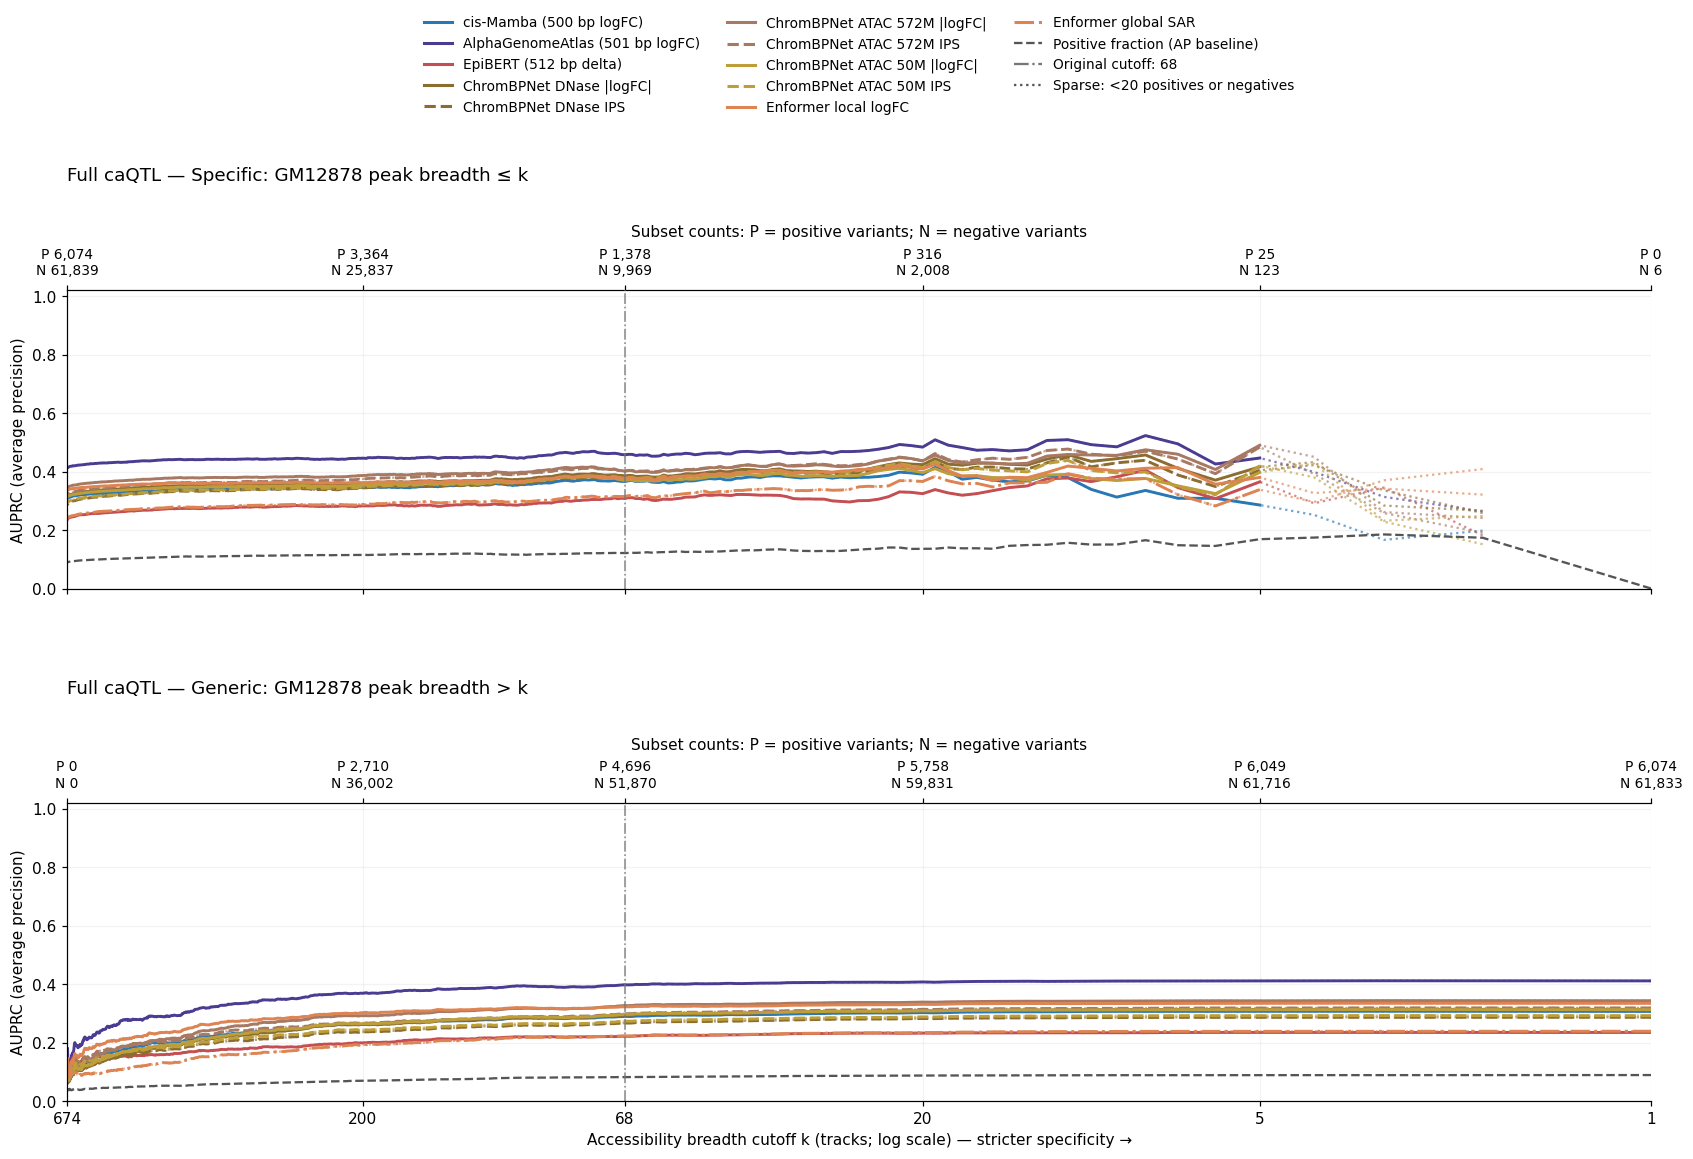

In [12]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from matplotlib.lines import Line2D

# Keep existing colors; distinguish alternative scores within the same model.
sweep_colors = {name: colors[name] for name in SWEEP_MODELS}
sweep_styles = {name: ('--' if name.endswith(' IPS') else
                       '-.' if name == 'Enformer global SAR' else '-')
                for name in SWEEP_MODELS}
fig, sweep_axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True, sharey=True)
fig.subplots_adjust(left=.08, right=.98, bottom=.09, top=.76, hspace=.72)

for ax, group, rule in zip(sweep_axes, ['Specific', 'Generic'], ['≤ k', '> k']):
    count = sweep_counts[sweep_counts.group == group].sort_values('cutoff').set_index('cutoff')
    for name in SWEEP_MODELS:
        data = sweep_results[(sweep_results.group == group) &
                             (sweep_results.model == name)].sort_values('cutoff')
        # A faint dotted trace displays supported but sparse estimates; the
        # solid overlay identifies portions with >=20 observations per class.
        ax.plot(data.cutoff, data.ap, color=sweep_colors[name], lw=1.5,
                ls=':', alpha=.65)
        ax.plot(data.cutoff, data.ap.where(~data.low_count),
                color=sweep_colors[name], lw=1.9, ls=sweep_styles[name], label=name)
    ax.plot(count.index, count.prevalence, color='#555555', ls='--', lw=1.5)
    ax.axvline(SPECIFICITY_CUTOFF, color='#777777', ls='-.', lw=1.1, alpha=.8)
    ax.set_xscale('log')
    ax.set_xlim(sweep_track_count, 1)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel('AUPRC (average precision)')
    ax.set_title(f'{SWEEP_COHORT} caQTL — {group}: GM12878 peak breadth {rule}', loc='left', pad=72, fontsize=12)
    ax.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    ax.xaxis.set_major_formatter(FixedFormatter([str(k) for k in SWEEP_COUNT_TICKS]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(alpha=.15)
    ax.set_axisbelow(True)
    count_axis = ax.secondary_xaxis('top')
    count_axis.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    count_axis.xaxis.set_major_formatter(FixedFormatter([
        f'P {int(count.loc[k, "positives"]):,}\nN {int(count.loc[k, "negatives"]):,}'
        for k in SWEEP_COUNT_TICKS]))
    count_axis.xaxis.set_minor_locator(NullLocator())
    count_axis.tick_params(axis='x', labelsize=9, pad=5)
    count_axis.set_xlabel('Subset counts: P = positive variants; N = negative variants',
                          fontsize=10, labelpad=7)

sweep_axes[-1].set_xlabel('Accessibility breadth cutoff k (tracks; log scale) — stricter specificity →')
handles = [Line2D([], [], color=sweep_colors[n], lw=2, ls=sweep_styles[n], label=n) for n in SWEEP_MODELS]
handles += [Line2D([], [], color='#555555', ls='--', label='Positive fraction (AP baseline)'),
            Line2D([], [], color='#777777', ls='-.', label='Original cutoff: 68'),
            Line2D([], [], color='#555555', ls=':', label='Sparse: <20 positives or negatives')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.53, .997),
           ncol=3, fontsize=9, frameon=False)
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.png', dpi=180, bbox_inches='tight')
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.pdf', bbox_inches='tight')
plt.show()


## Accessibility cutoff sweep on AlphaGenome's test subset

This repeats the full-cohort sweep above on **AlphaGenome's variant-benchmark
test chromosomes: 3, 6, 9, 12, 16, 18, 19, 21**. They are specified in the
**Chromosome Splits for Variant Benchmarks** section of the
[supplementary methods](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41586-025-10014-0/MediaObjects/41586_2025_10014_MOESM1_ESM.pdf).
These chromosome groups separate variant-scoring development from evaluation;
they do not make the distilled all-fold model a model trained without those
chromosomes' reference data.

The authors' released
[classification table](https://storage.googleapis.com/alphagenome/evals/caqtl_european_variant_causality_human_predictions.feather)
contains **31,621 variants: 2,618 positives and 29,003 controls**. Their released
[coefficient table](https://storage.googleapis.com/alphagenome/evals/caqtl_european_variant_coefficient_human_predictions.feather)
contains the **2,618 positives** and observed effects. The next cell checks
exact hg38 variant IDs, alleles encoded in those IDs, labels and positive effect
sizes against a saved reference extracted from those files. Source URLs and file
hashes are recorded beside it. Chromosome 9 has no variants in our parent
European var.isused cohort.

After excluding the **8,707 Other variants**, the sweep contains **22,914
variants within GM12878 merged peaks**. All models use this same subset, their
unchanged notebook scores, the same 674 integer cutoffs, and the same visual
conventions as above. This matches the published variant selection, not every
model/scorer detail of the paper. The published prediction values are not
substituted for our cached predictions.

Run the initial data/annotation/score cells through Complete shared support, then
these cells. The full-cohort sweep need not be rerun. Outputs are saved separately
under `caQTL_benchmark5_cutoff_sweep/alphagenome_test/`. The count flags are
descriptive, and the plot has no confidence bands.


In [11]:
# Validate against the released tables, independently of the chromosome rule.
AG_REFERENCE_DIR = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/caqtl/caQTL_benchmark5_cutoff_sweep/alphagenome_test')
ag_reference = pd.read_csv(AG_REFERENCE_DIR / 'released_variant_reference.tsv.gz', sep='\t')
require(not ag_reference.variant_id.duplicated().any(), 'Duplicate published variant ID.')
require((len(ag_reference), int(ag_reference.label.sum())) == (31621, 2618),
        'Released reference size/labels changed.')
ag_chromosome_mask = q['var.chr'].isin(AG_TEST_CHROMS).to_numpy()
ag_released_mask = q['variant_id'].isin(ag_reference.variant_id).to_numpy()
np.testing.assert_array_equal(ag_chromosome_mask, ag_released_mask,
                              err_msg='Chromosome filter differs from released variant identities.')
ag_selected = q.loc[ag_chromosome_mask].set_index('variant_id')
require(set(ag_selected.index) == set(ag_reference.variant_id), 'Missing or extra published variants.')
ag_reference = ag_reference.set_index('variant_id').loc[ag_selected.index]
np.testing.assert_array_equal(ag_selected.label, ag_reference.label)
ag_positive_ids = ag_reference.index[ag_reference.label.eq(1)]
np.testing.assert_allclose(ag_selected.loc[ag_positive_ids, 'obs.beta'],
                          ag_reference.loc[ag_positive_ids, 'observed_beta'],
                          rtol=1e-6, atol=1e-8)
ag_reference_counts = cohort_counts(ag_chromosome_mask)
np.testing.assert_array_equal(ag_reference_counts.loc[STRATA, 'Variants'], [19157, 8707, 3757])
display(ag_reference_counts)
print('Exact match to all 31,621 released variant IDs and labels; '
      '2,618 positive observed effects agree. Other is excluded only from the sweep.')


,Variants,Positives,Controls,Chance AP
Stratum,,,,
Overall,31621,2618,29003,0.082793
Generic,19157,1587,17570,0.082842
Other,8707,585,8122,0.067187
Specific,3757,446,3311,0.118712


Exact match to all 31,621 released variant IDs and labels; 2,618 positive observed effects agree. Other is excluded only from the sweep.


In [12]:
from time import perf_counter

sweep_started = perf_counter()
SWEEP_COHORT = 'AlphaGenome test'
SWEEP_MODELS = list(AP_NAMES)
SWEEP_MIN_CLASS_COUNT = 20  # display flag only; retains all scores/counts
require(SWEEP_COHORT in ['Full', 'AlphaGenome test'], 'Unknown sweep cohort.')
sweep_cohort = (full_mask.copy() if SWEEP_COHORT == 'Full' else
                q['var.chr'].isin(AG_TEST_CHROMS).to_numpy())
if SWEEP_COHORT == 'AlphaGenome test':
    require((int(sweep_cohort.sum()), int(y[sweep_cohort].sum())) == (31621, 2618),
            'AlphaGenome test-chromosome membership changed.')
sweep_slug = 'full' if SWEEP_COHORT == 'Full' else 'alphagenome_test'
SWEEP_OUT = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/caqtl') / 'caQTL_benchmark5_cutoff_sweep' / sweep_slug
SWEEP_OUT.mkdir(parents=True, exist_ok=True)

sweep_track_count = len(pd.read_csv(PEAK_CACHE / 'tracks.tsv', sep='\t'))
sweep_breadth = q['peak_breadth'].to_numpy(dtype=float)
sweep_in_peak = q['merged_peak_id'].fillna('').ne('').to_numpy()
np.testing.assert_array_equal(sweep_in_peak, q['stratum'].ne('Other').to_numpy())
sweep_support = sweep_cohort & sweep_in_peak
require(np.isfinite(sweep_breadth[sweep_support]).all(), 'Missing in-peak breadth.')
require((sweep_breadth[sweep_support] == np.floor(sweep_breadth[sweep_support])).all(),
        'Track breadth must be an integer.')
require(((sweep_breadth[sweep_support] >= 1) &
         (sweep_breadth[sweep_support] <= sweep_track_count)).all(), 'Invalid track breadth.')
require(bool(SWEEP_MODELS) and len(SWEEP_MODELS) == len(set(SWEEP_MODELS)),
        'Select at least one model, without duplicates.')
require(set(SWEEP_MODELS) <= set(classification_scores), 'Unknown classification arm.')
for name in SWEEP_MODELS:
    require(np.isfinite(classification_scores[name][sweep_support]).all(),
            f'{name}: nonfinite score on common sweep support.')
sweep_original_masks = cohort_masks(sweep_cohort)
np.testing.assert_array_equal(sweep_support & (sweep_breadth <= SPECIFICITY_CUTOFF),
                              sweep_original_masks['Specific'])
np.testing.assert_array_equal(sweep_support & (sweep_breadth > SPECIFICITY_CUTOFF),
                              sweep_original_masks['Generic'])

sweep_count_rows, sweep_score_rows = [], []
for cutoff in range(1, sweep_track_count + 1):
    for group, mask in [('Specific', sweep_support & (sweep_breadth <= cutoff)),
                        ('Generic', sweep_support & (sweep_breadth > cutoff))]:
        n = int(mask.sum())
        positive = int(y[mask].sum())
        negative = n - positive
        defined = positive > 0 and negative > 0
        sweep_count_rows.append(dict(cutoff=cutoff, group=group, variants=n,
            positives=positive, negatives=negative,
            prevalence=positive / n if n else np.nan,
            ap_defined=defined, low_count=min(positive, negative) < SWEEP_MIN_CLASS_COUNT,
            peak_clusters=int(q.loc[mask, 'merged_peak_id'].nunique())))
        for name in SWEEP_MODELS:
            ap = (average_precision_score(y[mask], classification_scores[name][mask])
                  if defined else np.nan)
            sweep_score_rows.append(dict(cutoff=cutoff, group=group, model=name, ap=ap))
    if cutoff % 100 == 0:
        print(f'Scored {cutoff}/{sweep_track_count} cutoffs.', flush=True)

sweep_counts = pd.DataFrame(sweep_count_rows)
sweep_results = pd.DataFrame(sweep_score_rows).merge(
    sweep_counts, on=['cutoff', 'group'], validate='many_to_one')
require(sweep_counts.groupby('cutoff').variants.sum().eq(int(sweep_support.sum())).all(),
        'Changing total sweep population across cutoffs.')
require(sweep_counts.groupby('cutoff').positives.sum().eq(int(y[sweep_support].sum())).all(),
        'Changing total sweep positive count across cutoffs.')
for group in ['Specific', 'Generic']:
    at_original = sweep_results[(sweep_results.cutoff == SPECIFICITY_CUTOFF) &
                                (sweep_results.group == group)].set_index('model')
    old_mask = sweep_original_masks[group]
    expected = [average_precision_score(y[old_mask], classification_scores[name][old_mask])
                if np.unique(y[old_mask]).size == 2 else np.nan for name in SWEEP_MODELS]
    np.testing.assert_allclose(at_original.loc[SWEEP_MODELS, 'ap'], expected,
                              rtol=0, atol=1e-12, equal_nan=True)

sweep_counts.to_csv(SWEEP_OUT / 'cutoff_counts.tsv', sep='\t', index=False)
sweep_results.to_csv(SWEEP_OUT / 'cutoff_model_ap.tsv', sep='\t', index=False)
(SWEEP_OUT / 'config.json').write_text(json.dumps({
    'cohort': SWEEP_COHORT, 'models': SWEEP_MODELS, 'cutoffs': [1, sweep_track_count],
    'score_definitions': {name: score_definitions[name] for name in SWEEP_MODELS},
    'specific_rule': 'GM12878 merged peak breadth <= cutoff',
    'generic_rule': 'GM12878 merged peak breadth > cutoff',
    'other_excluded': True, 'source_sha256': SOURCE_SHA256,
    'annotation': str(PEAK_FILE), 'annotation_sha256': sha256(PEAK_FILE),
    'metric': 'sklearn.metrics.average_precision_score',
    'original_cutoff': SPECIFICITY_CUTOFF,
    'low_count_display_threshold_per_class': SWEEP_MIN_CLASS_COUNT,
    'confidence_intervals': False,
}, indent=2) + '\n')
SWEEP_COUNT_TICKS = sorted({1, 5, 20, SPECIFICITY_CUTOFF, 200, sweep_track_count})
display(sweep_counts[sweep_counts.cutoff.isin(SWEEP_COUNT_TICKS)]
        .sort_values(['group', 'cutoff'], ascending=[False, False]))
print(f'{SWEEP_COHORT}: {sweep_support.sum():,} in-peak variants; '
      f'{int(y[sweep_support].sum()):,} positives. '
      f'Excluded Other: {int((sweep_cohort & ~sweep_in_peak).sum()):,} variants. '
      f'Scored {sweep_track_count:,} cutoffs for {len(SWEEP_MODELS)} arms in '
      f'{perf_counter() - sweep_started:.1f} s. Outputs: {SWEEP_OUT}')


,cutoff,group,variants,positives,negatives,prevalence,ap_defined,low_count,peak_clusters
1346,674,Specific,22914,2033,20881,0.088723,True,False,12689
398,200,Specific,9646,1104,8542,0.114452,True,False,5647
134,68,Specific,3757,446,3311,0.118712,True,False,2348
38,20,Specific,812,116,696,0.142857,True,False,485
8,5,Specific,55,12,43,0.218182,True,True,35
0,1,Specific,5,0,5,0.000000,False,True,3
1347,674,Generic,0,0,0,NaN,False,True,0
399,200,Generic,13268,929,12339,0.070018,True,False,7042
135,68,Generic,19157,1587,17570,0.082842,True,False,10341
39,20,Generic,22102,1917,20185,0.086734,True,False,12204


Scored 100/674 cutoffs.
Scored 200/674 cutoffs.
Scored 300/674 cutoffs.
Scored 400/674 cutoffs.
Scored 500/674 cutoffs.
Scored 600/674 cutoffs.
AlphaGenome test: 22,914 in-peak variants; 2,033 positives. Excluded Other: 8,707 variants. Scored 674 cutoffs for 11 arms in 33.5 s. Outputs: /data1/lesliec/sarthak/caduceus/notebooks/benchmarks/caqtl/caQTL_benchmark5_cutoff_sweep/alphagenome_test


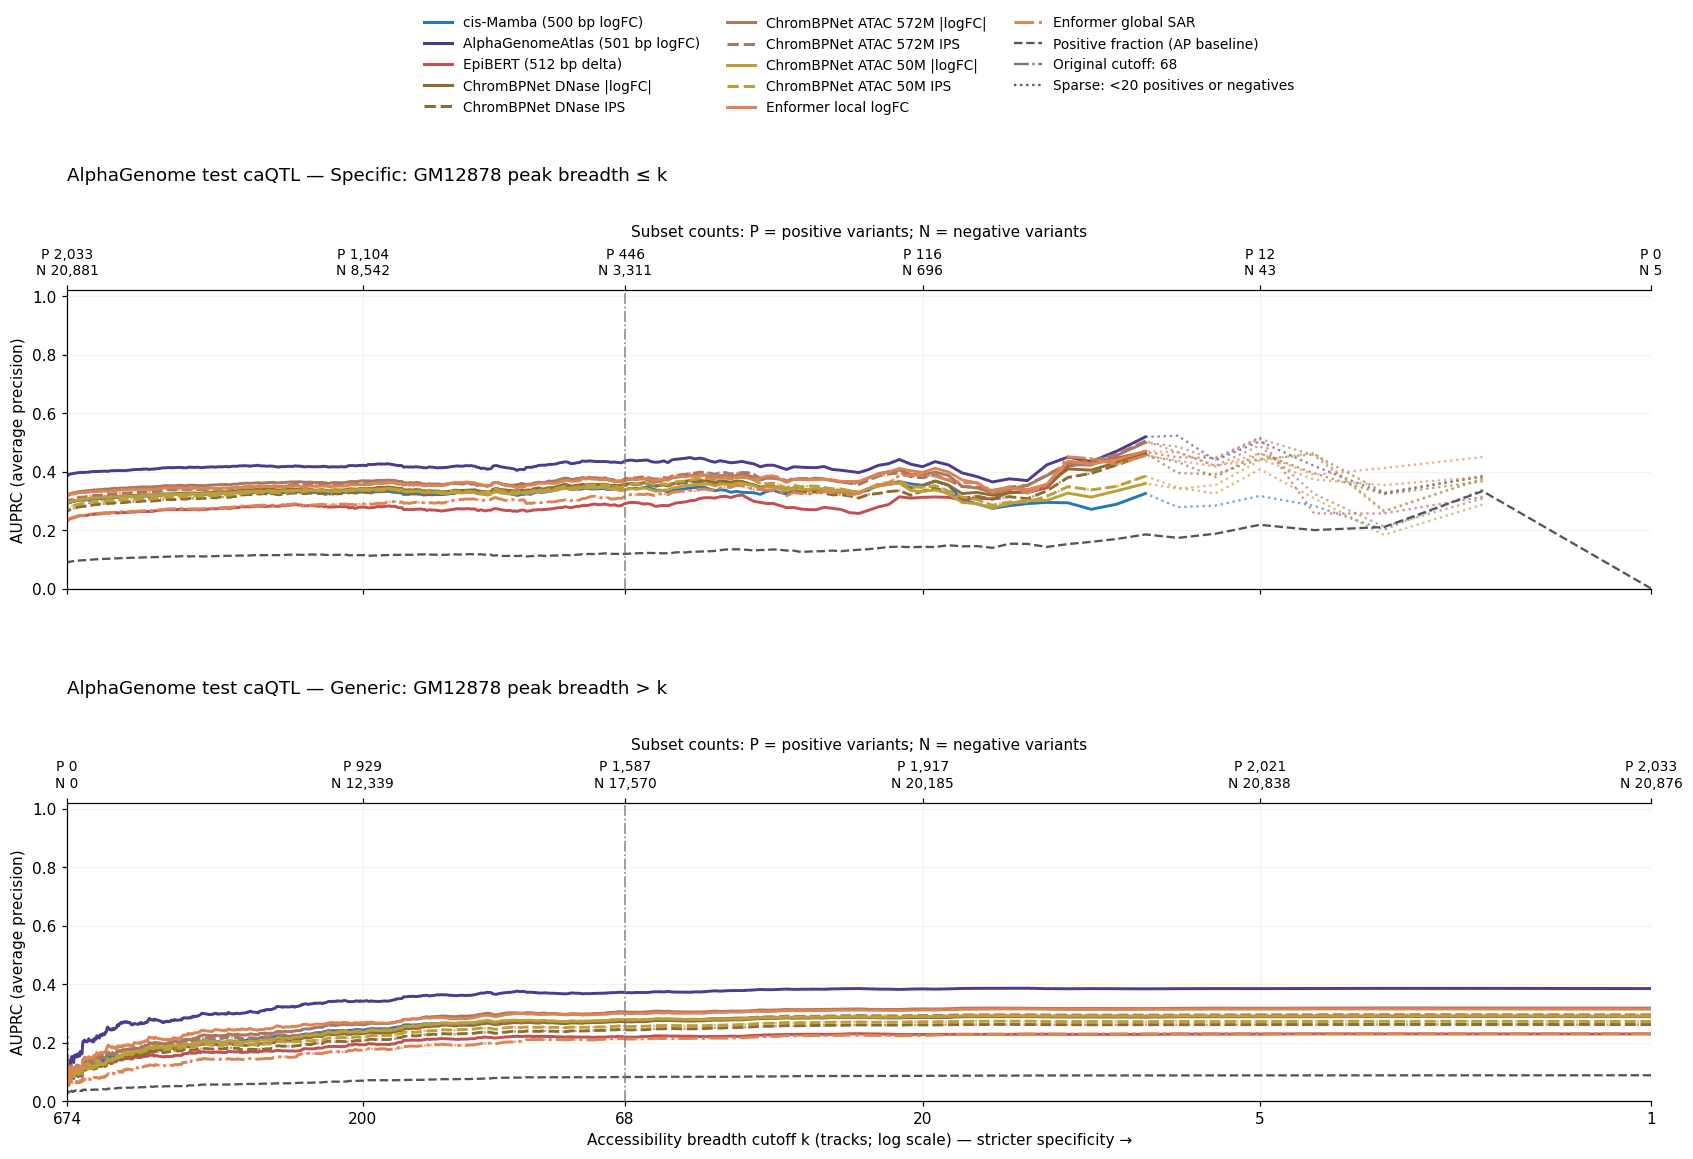

In [13]:
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator
from matplotlib.lines import Line2D

# Keep existing colors; distinguish alternative scores within the same model.
sweep_colors = {name: colors[name] for name in SWEEP_MODELS}
sweep_styles = {name: ('--' if name.endswith(' IPS') else
                       '-.' if name == 'Enformer global SAR' else '-')
                for name in SWEEP_MODELS}
fig, sweep_axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True, sharey=True)
fig.subplots_adjust(left=.08, right=.98, bottom=.09, top=.76, hspace=.72)

for ax, group, rule in zip(sweep_axes, ['Specific', 'Generic'], ['≤ k', '> k']):
    count = sweep_counts[sweep_counts.group == group].sort_values('cutoff').set_index('cutoff')
    for name in SWEEP_MODELS:
        data = sweep_results[(sweep_results.group == group) &
                             (sweep_results.model == name)].sort_values('cutoff')
        # A faint dotted trace displays supported but sparse estimates; the
        # solid overlay identifies portions with >=20 observations per class.
        ax.plot(data.cutoff, data.ap, color=sweep_colors[name], lw=1.5,
                ls=':', alpha=.65)
        ax.plot(data.cutoff, data.ap.where(~data.low_count),
                color=sweep_colors[name], lw=1.9, ls=sweep_styles[name], label=name)
    ax.plot(count.index, count.prevalence, color='#555555', ls='--', lw=1.5)
    ax.axvline(SPECIFICITY_CUTOFF, color='#777777', ls='-.', lw=1.1, alpha=.8)
    ax.set_xscale('log')
    ax.set_xlim(sweep_track_count, 1)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel('AUPRC (average precision)')
    ax.set_title(f'{SWEEP_COHORT} caQTL — {group}: GM12878 peak breadth {rule}', loc='left', pad=72, fontsize=12)
    ax.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    ax.xaxis.set_major_formatter(FixedFormatter([str(k) for k in SWEEP_COUNT_TICKS]))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(alpha=.15)
    ax.set_axisbelow(True)
    count_axis = ax.secondary_xaxis('top')
    count_axis.xaxis.set_major_locator(FixedLocator(SWEEP_COUNT_TICKS))
    count_axis.xaxis.set_major_formatter(FixedFormatter([
        f'P {int(count.loc[k, "positives"]):,}\nN {int(count.loc[k, "negatives"]):,}'
        for k in SWEEP_COUNT_TICKS]))
    count_axis.xaxis.set_minor_locator(NullLocator())
    count_axis.tick_params(axis='x', labelsize=9, pad=5)
    count_axis.set_xlabel('Subset counts: P = positive variants; N = negative variants',
                          fontsize=10, labelpad=7)

sweep_axes[-1].set_xlabel('Accessibility breadth cutoff k (tracks; log scale) — stricter specificity →')
handles = [Line2D([], [], color=sweep_colors[n], lw=2, ls=sweep_styles[n], label=n) for n in SWEEP_MODELS]
handles += [Line2D([], [], color='#555555', ls='--', label='Positive fraction (AP baseline)'),
            Line2D([], [], color='#777777', ls='-.', label='Original cutoff: 68'),
            Line2D([], [], color='#555555', ls=':', label='Sparse: <20 positives or negatives')]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(.53, .997),
           ncol=3, fontsize=9, frameon=False)
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.png', dpi=180, bbox_inches='tight')
fig.savefig(SWEEP_OUT / 'accessibility_cutoff_sweep.pdf', bbox_inches='tight')
plt.show()
